# Notebook 03: Indivisibility — Where Quantum Processes Live

**Goal:** Construct a process that fails the divisibility test and understand
exactly why — negative entries in the intermediate matrix.

By the end of this notebook you will be able to:
- Construct an indivisible stochastic process from a qubit unitary
- Identify which failure mode is triggered and at which times
- Compute the indivisibility signature and interpret its value
- See indivisibility in a smooth, non-quantum 2×2 matrix and explain it as lost-then-recovered information


<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

---
> ### 📓 Annotated study copy
>
> Working copy of `03_indivisibility.ipynb`. Added sections are marked **📖 In depth**,
> **🔍 Reading the code**, and **🔧** (code cells that differ from the clean notebook).
>
> Two code cells differ from the clean notebook:
>
> | cell | what this copy does |
> |---|---|
> | "Step transition matrices" | prints the two *given* matrices, $T(t_1 \to t_2)$ and $T(t_1 \to t_3)$, separately from the *derived* intermediate $T(t_2 \to t_3)$. The stored step `proc.transitions[1]` is that derived intermediate, $\begin{smallmatrix}1.1124 & -0.1124\\ -0.1124 & 1.1124\end{smallmatrix}$; the matrix $\lvert U(0.2618)\rvert^2$ for the same elapsed time is the valid $\begin{smallmatrix}0.983 & 0.017\\ 0.017 & 0.983\end{smallmatrix}$. |
> | ω sweep | plots the signature on a log axis, so the 16.35 peak does not flatten everything else, and marks the 29 zero-signature points as "divisible at these times" |
>
> Companion to `01_stochastic_processes_annotated.ipynb` and `02_divisibility_annotated.ipynb`.
>
> Sections on the inverse-free divisibility test and `PairwiseProcess` cover the cases where
> the inverse-based test is structurally unavailable rather than merely inconclusive.
>
> Section 3 works through the Gaussian example from Barandes's Paper 1 (eq. 7) and lecture *A New Formulation of
> Quantum Theory* (~17 min). It carries the same cells as `03_indivisibility.ipynb`, plus
> annotated-only cells: a plain-words version, the full derivation, Case 3 as a word problem,
> a rule-space picture, a Hilbert-space/division-event view, and a tie-in to the 🔭 cell in Section 2.
---

<!-- expansion:03:before-you-start -->
### 🧭 Before you start

**What this notebook is for.** Notebooks 01 and 02 built the *divisibility* test: can the evolution from an early time to a late time be split into two legitimate probabilistic legs? This notebook is where that test **fails**.

1. **Section 1** turns a qubit's evolution into an ordinary table of probabilities and shows it cannot be split at an intermediate time without negative "probabilities".
2. **Section 2** turns that failure into a number, the *indivisibility signature*, and explains why it is a detector, not a gauge.
3. **Section 3** shows the same failure in a matrix with no quantum mechanics in it (the Gaussian from Barandes's lecture and Paper 1), explained as information "lost and then recovered".

**Prerequisites.**

- Notebook 01 (`01_stochastic_processes_annotated.ipynb`): what a column-stochastic matrix is, and why columns must sum to 1.
- Notebook 02 (`02_divisibility_annotated.ipynb`): the divisibility condition, the inverse-based test `check_divisibility()`, and the inverse-free linear-program test. Section 3 reuses the latter.
- Comfort with 2×2 matrix multiplication, matrix inverses and determinants. Complex numbers appear only in Section 1 and only as $|z|^2$ (the squared size of a complex number).

No quantum mechanics is assumed beyond what the notebook states. The glossary below defines every term the notebook uses.

**How long.** About 45–60 minutes to read carefully, longer if you try the experiments suggested in the 🧭 cells. Section 1 is the core; Section 3 is the most visual and the easiest place to build intuition.

**How to run it.**

- Use **Kernel → Restart & Run All** to reproduce everything from a clean state, or step through with **Shift+Enter**.
- The first code cell adds the parent folder (`isp-lab/`) to Python's import path with `sys.path.insert(0, os.path.abspath('..'))`. That means the notebook must be opened **from inside the `notebooks/` folder**. The helper functions come from the local `isp/` package one level up: `isp/quantum.py`, `isp/divisibility.py`, `isp/stochastic.py`, `isp/visualization.py`.
- Dependencies: NumPy, Matplotlib, SciPy (`expm` and the HiGHS solver used by `_intermediate_lp`).
- The 🧭 cells quote the stored outputs. If a re-run gives different numbers, something in `isp/` has changed.

**Added cell labels.** On top of the existing 📖 / 🔍 / 🔧 / 🔭 cells: **📘 Glossary**; **📚 From the papers** (what the papers, lecture or standard references say, with a section, equation number or quoted phrase so you can check); **🧭 How to use this cell** (what a code cell computes, which numbers matter, experiments with predictions); **🧮 Worked derivation**; **📝 Recap**.


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.quantum import make_qubit_sigmax_process
from isp.divisibility import check_divisibility, indivisibility_signature
from isp.visualization import plot_transition_matrix

<!-- expansion:03:glossary -->
### 📘 Glossary

Terms are grouped by where they first matter. Symbols follow the notebook: $T$ in Sections 1–2, $\Gamma$ in Section 3. They mean the same kind of object.

**Probability side**

- **State / configuration.** One of the possible values the system can take; here always two, labelled 0 and 1. Barandes calls these *configurations*.
- **Transition matrix $T(t \leftarrow t_0)$ or $\Gamma(t \leftarrow t_0)$.** Entry $(i, j)$ is the probability of being in state $i$ at time $t$ *given* state $j$ at time $t_0$. Column $j$ is "where the runs that started in $j$ end up". It is read right-to-left: the arrow points from the conditioning time $t_0$ to the target time $t$.
- **Column-stochastic matrix (valid matrix).** Every entry $\ge 0$ and every column sums to 1, so it maps probability vectors to probability vectors.
- **Doubly stochastic (bistochastic).** Rows also sum to 1, as for every given matrix in this notebook.
- **Pseudo-stochastic matrix.** Columns sum to 1, but some entries are negative. The "candidate" intermediates that fail in this notebook are pseudo-stochastic. (The term is used in Paper 3, §2.2.)
- **Composition law / divisibility condition.** $T(t \leftarrow t_0) = \tilde T(t \leftarrow t')\,T(t' \leftarrow t_0)$ for an intermediate time $t'$, with $\tilde T$ a *valid* stochastic matrix.
- **Divisible.** The composition law can be satisfied, with a valid $\tilde T$, for the intermediate times considered.
- **Indivisible.** For at least one choice of times, no valid $\tilde T$ exists.
- **Candidate intermediate.** $T(t \leftarrow t_0)\,T(t' \leftarrow t_0)^{-1}$: the only matrix that could serve as $\tilde T$ when $T(t' \leftarrow t_0)$ is invertible.
- **Markov process / Markov chain.** A process whose future depends only on its present state, not on how it got there. A continuous-time Markov chain has $T(t \leftarrow t') = e^{L(t-t')}$ for a fixed **generator** $L$ (off-diagonal entries $\ge 0$, columns summing to 0). Markov implies divisible (notebook 02).
- **Non-Markovian.** Has memory: the future depends on more than the present state. Indivisible implies non-Markovian, but not the other way round.
- **Division event.** In Barandes's papers, a time that can serve as a valid conditioning time for the process. Interactions with an environment can create one (see the 📚 cell near the end of Section 3).

**Linear-algebra side**

- **Determinant ($\det$); invertible / singular.** $\det$ is zero exactly when the matrix is **singular**: it has no inverse, so the input cannot be recovered from the output. For the 2×2 matrices here, $\det$ measures how much the matrix still distinguishes the two starting states.
- **Eigenvector / eigenvalue.** A direction a matrix only stretches, and the stretch factor. Every matrix here has eigenvectors $(1,1)$ and $(1,-1)$.
- **Stretch $s$ (Section 3), also $\lambda(t)$.** For a matrix $\begin{pmatrix} a & 1-a \\ 1-a & a\end{pmatrix}$, $s = 2a - 1$, the eigenvalue on $(1,-1)$. It equals the determinant. Valid exactly when $|s| \le 1$.
- **Linear program (LP).** Here: "does any non-negative matrix with unit column sums satisfy $M\,T(t'\leftarrow t_0) = T(t\leftarrow t_0)$?" **HiGHS** is the solver SciPy uses. **Farkas' lemma** guarantees an infeasible LP has a checkable certificate (see the 📖 cell in Section 1).

**Quantum side (Section 1 and the end of Section 3)**

- **Qubit.** A two-state quantum system. Its **computational-basis states** $|0\rangle$, $|1\rangle$ play the role of the two configurations.
- **Amplitude; Born rule.** An amplitude is a complex number attached to a transition. The Born rule says probabilities are their squared sizes, $|z|^2$.
- **Unitary matrix $U$.** A complex matrix with $U^\dagger U = 1$; its columns are unit vectors. Closed quantum systems evolve by unitaries (Nielsen & Chuang, *Postulate 2*).
- **Hamiltonian $H$; $\sigma_x$.** $H$ generates the unitary, $U(t) = e^{-iHt}$. Here $H = \tfrac{\omega}{2}\sigma_x$ with $\sigma_x = \begin{pmatrix}0&1\\1&0\end{pmatrix}$ (Pauli X, the quantum NOT), which rotates the qubit steadily between $|0\rangle$ and $|1\rangle$.
- **Unistochastic matrix.** A stochastic matrix whose entries are $|U_{ij}|^2$ for some unitary $U$.
- **Interference / cross terms.** The part of $|\sum_k z_k|^2$ that is not $\sum_k |z_k|^2$. It is what a probability calculation misses if it squares amplitudes too early.
- **Hilbert-space representation.** A way of writing a stochastic process with amplitudes and unitaries so that squaring gives back the probabilities. Barandes's theorem says one always exists (possibly in a bigger space).
- **Gauge freedom (Section 3).** Different choices of phases on the amplitudes give the same probabilities $\Gamma(t \leftarrow 0)$ and, by Barandes's gauge-invariance result, the same empirical predictions (Paper 1, footnote 6; Paper 3, §3.2).

**This notebook's own terms**

- **Indivisibility signature.** The size of the most negative entry found in any candidate intermediate, as computed by `indivisibility_signature()`. Zero means "no failure detected at these times".
- **$\tau$ and $t^*$ (Section 3).** $\tau$ is the time scale of the Gaussian; times are in units of $\tau$. $t^* = \tau\sqrt{\ln 2} \approx 0.833\,\tau$ is the instant the Gaussian matrix becomes a coin flip.
- **Gap.** In Section 3, the distance between the two "dots" (the probability of state 0 for runs that started in 0 vs. in 1). It equals $|\lambda(t)|$.


## 1. A Process From Quantum Mechanics

Consider a qubit evolving under $H = \frac{\omega}{2}\sigma_x$.
The unitary is:
$$U(dt) = e^{-iH\,dt} = \begin{pmatrix} \cos\tfrac{\omega\,dt}{2} & -i\sin\tfrac{\omega\,dt}{2} \\ -i\sin\tfrac{\omega\,dt}{2} & \cos\tfrac{\omega\,dt}{2} \end{pmatrix}$$

The stochastic transition matrix takes $|U_{ij}|^2$:
$$T(dt) = \begin{pmatrix} \cos^2\tfrac{\omega\,dt}{2} & \sin^2\tfrac{\omega\,dt}{2} \\ \sin^2\tfrac{\omega\,dt}{2} & \cos^2\tfrac{\omega\,dt}{2} \end{pmatrix}$$

This is the second example in Barandes's Paper 1 (§2.1, eq. 7: $f(t) = \cos^2\omega t$, his $\omega$ being our $\omega/2$), which he calls "provably indivisible"; this notebook checks it numerically.

Each column sums to 1. All entries are non-negative. Looks perfectly classical — or does it?

<!-- expansion:03:papers-divisibility-def -->
### 📚 From the papers: what "divisible" means, and the two examples Barandes uses

The whole notebook tests one condition. Here it is in the original sources, so you can see that the code is testing the right thing.

**The definition (Paper 1, §2, eq. 6).** *The Stochastic-Quantum Correspondence* states that the transition matrix "will generically be indivisible ..., meaning that for intermediate times $t'$ satisfying $t > t' > t_0$, there will not generally exist a genuinely stochastic matrix $\tilde\Gamma(t \leftarrow t')$ satisfying the composition law or divisibility condition"

$$\Gamma(t \leftarrow t_0) = \tilde\Gamma(t \leftarrow t')\,\Gamma(t' \leftarrow t_0). \qquad \text{(Paper 1, eq. 6)}$$

For "generically indivisible", Paper 1 cites Milz and Modi (2021).

In plain words: you are handed the matrices from the start time $t_0$ to every later time. The process is divisible across $t'$ if there is some *legitimate* probability table that carries you from $t'$ to $t$ and reproduces those given matrices. In this notebook, $t_0, t', t$ are called $t_1, t_2, t_3$ in Section 1 and $0, t', t$ in Section 3.

**Where the word comes from.** Paper 1 says the term "seems to have originated in the research literature in a 2008 paper by Wolf and Cirac (2008) in the context of quantum channels" (in the sources as `dividing_quantum_channels.txt`). Wolf and Cirac ask whether *one* channel factors into *any* non-trivial product; Barandes asks whether a *time-indexed family* factors through the matrix at a *specific* intermediate time. The notebook uses Barandes's sense. Paper 1 (footnote 4) also warns it is "conceptually distinct from the much older concept of infinite divisibility".

**The two examples (Paper 1, §2, eq. 7).** Paper 1 gives 2×2 transition matrices of the form

$$\Gamma(t \leftarrow 0) = \begin{pmatrix} f(t) & 1 - f(t) \\ 1 - f(t) & f(t) \end{pmatrix}$$

"for $f(t) \equiv \exp(-t^2/\tau^2)$ ... or for $f(t) \equiv \cos^2 \omega t$", and says both "are provably indivisible, because any matrix $\tilde\Gamma(t \leftarrow t')$ satisfying the divisibility condition above would need to have negative entries for at least some pairs of times $t$ and $t'$".

Those are exactly the two examples in this notebook:

- **The cosine example is Section 1's qubit.** The notebook writes $\cos^2(\omega t/2)$ because it uses $H = \tfrac{\omega}{2}\sigma_x$. Paper 1's $\cos^2(\omega t)$ is the same matrix with the paper's $\omega$ equal to the notebook's $\omega/2$. That is a choice of what to call $\omega$, nothing more; this notebook uses $\cos^2(\omega t/2)$ throughout, so its determinant is $\cos(\omega t)$.
- **The Gaussian example is Section 3.**

Notice the claim's careful wording: "for at least some pairs of times". Indivisibility is a statement that *some* split fails, not that every split fails. Section 2's 29 zeros and Section 3's map of valid and invalid $(t', t)$ pairs both illustrate that phrase.


### 📖 In depth: where exactly does the quantumness enter?

The markdown above ends with *"Looks perfectly classical — or does it?"* — which is the right question, but the answer is more specific than "it isn't."

#### The setup is genuinely, unimpeachably classical

Everything handed to us is a legitimate probabilistic object:

* $U(t)$ is unitary, so each column is a unit vector;
* therefore $T(t,t_0)_{ij} = |U(t)_{ij}|^2$ has non-negative entries whose columns sum to $\sum_i |U_{ij}|^2 = 1$;
* so **every** $T(t, t_0)$ is a bona fide stochastic matrix, at every time, no exceptions.

There is no sleight of hand. A qubit really does define an honest stochastic process over the two computational-basis states. The next cell verifies this against the closed form.

#### The failure is in composition, not in any individual matrix

Here is the mechanism, stated precisely.

Quantum evolution composes perfectly **at the level of amplitudes**:

$$U(a+b) = U(b)\,U(a) \qquad \text{(exact, to machine precision)}$$

But the map to probabilities, $M \mapsto |M|^2$ entrywise, **does not commute with matrix multiplication**:

$$\big|U(b)\,U(a)\big|^2 \;\neq\; \big|U(b)\big|^2\,\big|U(a)\big|^2$$

Write out one entry to see why:

$$\Big|\sum_k U(b)_{ik}\,U(a)_{kj}\Big|^2 \;=\; \underbrace{\sum_k \big|U(b)_{ik}\big|^2\big|U(a)_{kj}\big|^2}_{\text{the classical, path-summed term}} \;+\; \underbrace{\sum_{k \neq l} U(b)_{ik}U(a)_{kj}\overline{U(b)_{il}U(a)_{lj}}}_{\textbf{cross terms — interference}}$$

The first term is exactly what a stochastic matrix product would give: sum over intermediate states $k$, multiplying probabilities along each path. The second term is the residue of the **relative phases** between paths — the thing $|\cdot|^2$ throws away when applied too early.

> **This is the source of the qubit's indivisibility in one line.** Classical probability requires summing over intermediate states. Quantum mechanics sums over intermediate *amplitudes* and squares afterwards. Those differ by the cross terms. When the cross terms are large enough, they push the required intermediate matrix outside the space of stochastic matrices entirely. Interference does not always do this (at $t_2 = \pi/4$, $t_3 = \pi/3$ the cross terms are present but the intermediate stays valid), and Section 3 shows the same failure in a matrix written directly as probabilities, with no amplitudes at all.

#### Why negative entries specifically

The composite $T(t_3,t_1)$ is fixed by physics — it is $|U(t_3-t_1)|^2$, and it is valid. The first leg $T(t_2,t_1)$ is likewise fixed and valid. So the intermediate is forced:

$$T(t_3,t_2) = T(t_3,t_1)\,T(t_2,t_1)^{-1}$$

If interference has made $T(t_3,t_1)$ *more concentrated* than any classical composition through $t_2$ could produce, the only way to recover it is for the intermediate to **subtract** probability along some paths. Subtracting probability means negative entries. As notebook 01 showed, the column sums survive this untouched — nothing is created or destroyed, it is only pushed below zero and compensated above one.

Negative entries are therefore not a numerical artifact or a modelling failure. They mark interference that no classical factorization through $t_2$ can absorb. Their size is not a clean measure of that interference: Section 2 shows it mostly tracks how close $T(t_2,t_1)$ is to singular.

<!-- expansion:03:papers-unistochastic -->
### 📚 From the papers: $|U_{ij}|^2$ is a dictionary entry, not an approximation

The step $T_{ij} = |U_{ij}|^2$ in the Section 1 header can look like a trick. In Barandes's framework it is the central formula, and it has a name.

**Unistochastic matrices (Paper 1, §3.4, eq. 30; Paper 2, §3.5, eq. 68).** When a process's transition matrix satisfies

$$\Gamma_{ij}(t \leftarrow 0) = |U_{ij}(t \leftarrow 0)|^2 \qquad \text{(Paper 1, eq. 30)}$$

for a unitary $U$, "the system's transition matrix $\Gamma(t \leftarrow 0)$ is then said to be a unistochastic matrix", one "whose individual entries are the modulus-squares of the corresponding entries of a unitary matrix". Paper 1 traces the idea to Horn (1954), who called them "ortho-stochastic", and the modern name to Thompson (1989). Today "orthostochastic" is reserved for the case where $U$ can be chosen real.

**Why the sums come out right.** A unitary's columns and rows are unit vectors, so Paper 2 (§3.5): "Every unistochastic matrix is doubly stochastic or bistochastic, meaning that its columns and its rows each sum to 1." Section 1's matrices pass the validity check by construction.

**Two-state processes are the easy case.** Paper 2 (§3.5): "All 2 × 2 doubly stochastic matrices are unistochastic". It then gives a 3×3 doubly stochastic matrix that is "provably not unistochastic" (footnote 9). This is why both of this notebook's examples, the qubit and the Gaussian, can be written as $|U|^2$ without any extra machinery. It is also why the 🔭 cell at the end of Section 3 calls 2×2 "the easy case".

**The lecture's version of the same step.** In *A New Formulation of Quantum Theory* (~17–18 min), Barandes introduces the squared-modulus form as a re-description rather than a physical assumption: "This is not an axiom or [postulate]. It's a mathematical identity. I can just take the square root of the entries if I want." He adds that squares are a choice: "you don't have to use squares. You can use fourth power, fifth power. You just won't get Hilbert space picture". (Quoted from the auto-generated transcript, which renders the bracketed word as "positive".)

**So** the qubit is not "approximated" by a stochastic process: its computational-basis probabilities *are* one, exactly. The only question is whether it divides.


### 📖 In depth: the $\sigma_x$ qubit in closed form, and exactly when it breaks

The sweep later in this notebook has a spike at $16.35$, twenty-nine zeros, and a scattering of ordinary values, and the caveats cell treats those as things to be careful about. They are better than that: for this process every one of them is **predictable in closed form**, and deriving where they come from turns the sweep from a warning into a map.

#### The absolute matrix, and its determinant

With $H = \tfrac{\omega}{2}\sigma_x$ and $\theta \equiv \omega t / 2$,

$$U(t) = \cos\theta\, I - i \sin\theta\, \sigma_x
\qquad\Longrightarrow\qquad
T(t,t_0) = |U(t)|^2 = \begin{pmatrix} \cos^2\theta & \sin^2\theta \\ \sin^2\theta & \cos^2\theta \end{pmatrix}$$

Take the determinant and something clean happens:

$$\det T(t,t_0) \;=\; \cos^4\theta - \sin^4\theta \;=\; \big(\cos^2\theta - \sin^2\theta\big)\big(\underbrace{\cos^2\theta + \sin^2\theta}_{=\,1}\big) \;=\; \cos 2\theta \;=\; \boxed{\cos(\omega t)}$$

So the conditioning of the whole test is governed by a cosine. Everything the sweep does follows:

| where | $\det T$ | what the inverse-based test does |
|---|---|---|
| $\omega t$ near a multiple of $\pi$ | near $\pm 1$ | well conditioned, honest small signature |
| $\omega t$ approaching an odd multiple of $\pi/2$ | $\to 0$ | inverse blows up, signature spikes — **16.35 lives here**, at $\omega t_2 \approx 3\pi/2$ |
| $\omega t$ exactly an odd multiple of $\pi/2$ | $0$ | singular; `indivisibility_signature` skips it, scoring $0.0$ |

The spike comes from the cosine crossing zero: just *before* the crossing the matrix is nearly singular and the inverse explodes; *at* the crossing it is exactly singular and the triple is skipped, scoring $0.0$. None of the sweep's 50 values of $\omega$ lands on a crossing (the smallest $|\det T(t_1 \to t_2)|$ on the grid is $0.0144$, at the peak), so the 29 zeros are not skipped triples. They are genuine "divisible at these times" results, where $|\cos \omega t_3| \le |\cos \omega t_2|$, as the 🧮 cells derive.

> This is why the caveats cell insists the signature is a detector rather than a metric. Its magnitude is largely reporting $1/|\cos \omega t|$ — a fact about the sampling times, not about the physics.

#### What the singular time *is*, physically

At $\omega t = \pi/2$ the transition matrix is

$$T = \begin{pmatrix} 0.5 & 0.5 \\ 0.5 & 0.5 \end{pmatrix}$$

Rank 1. Both columns identical, both rows identical. Read it as a channel: **whatever distribution goes in, a coin flip comes out.** The process has completely forgotten its initial condition, which is exactly why the matrix cannot be inverted — inversion means recovering the input from the output, and there is nothing left to recover.

And notice *why* the rows coincide. At $\theta = \pi/4$ the unitary sends each basis state to a **balanced superposition**,

$$U(\pi/2) = \tfrac{1}{\sqrt 2}\begin{pmatrix} 1 & -i \\ -i & 1 \end{pmatrix}
\qquad\Longrightarrow\qquad
|U|^2 \text{ has both rows } (\tfrac12, \tfrac12)$$

Equal amplitudes to two destinations force equal rows in $|U|^2$, and equal rows force rank deficiency.

> 🔭 **Hold on to that sentence — it is the double slit in miniature.** Notebook 05's $\Gamma(t_1,t_0)$ is singular for precisely this reason: the source is prepared in the balanced superposition $(|A\rangle + |B\rangle)/\sqrt 2$, so rows $A$ and $B$ of $|U_1|^2$ are identical and the matrix is rank-deficient at every model size. The qubit meets that pathology at isolated instants; the double slit is built to sit in it permanently, which is why notebook 05 needed a test that never inverts anything.

<!-- expansion:03:deriv-qubit-stretch -->
### 🧮 Worked derivation: predicting $1.1124$ and $-0.1124$ before running anything

The closed-form cell above derived $\det T = \cos(\omega t)$. Combine that with Section 3's *stretch rule* and you can predict the negative entry printed below by hand. (Section 3 derives the stretch rule in full. It applies here unchanged, because the qubit's matrices have the same symmetric shape.)

**Step 1: the stretch of each given matrix.** For a matrix $\begin{pmatrix} a & 1-a \\ 1-a & a\end{pmatrix}$ the stretch is $s = 2a - 1$, which equals its determinant. With $a = \cos^2\theta$ and $\theta = \omega t/2$,

$$s(t) = 2\cos^2\tfrac{\omega t}{2} - 1 = \cos(\omega t).$$

**Step 2: plug in the notebook's times** ($\omega = 1$, $t_1 = 0$, $t_2 = 3\pi/4$, $t_3 = 5\pi/6$):

$$s(t_2) = \cos\tfrac{3\pi}{4} = -0.7071, \qquad s(t_3) = \cos\tfrac{5\pi}{6} = -0.8660.$$

**Step 3: the candidate's stretch is the ratio.** Stretches multiply under composition and invert under inversion, so

$$s_{\text{candidate}} = \frac{s(t_3)}{s(t_2)} = \frac{-0.8660}{-0.7071} = 1.2247 \;(= \sqrt{3/2}).$$

**Step 4: turn the stretch back into entries.** The diagonal is $a = (1 + s)/2 = 1.1124$ and the off-diagonal is $1 - a = -0.1124$. That is the matrix printed three times below, with min entry $-0.112372$.

**What the derivation tells you that the printout does not.**

- **The failure condition is a single inequality:** the candidate is invalid exactly when $|\cos \omega t_3| > |\cos \omega t_2|$. In words, the matrix at $t_3$ distinguishes the two starting states *better* than the matrix at $t_2$ did. Here $0.866 > 0.707$, so it fails.
- **The signature has a formula.** When $|s| > 1$ the most negative entry is $(1 - |s|)/2$, so the signature is $(|s| - 1)/2$. For $s = 1.2247$ that gives $0.1124$. Section 2 uses this to explain the 16.35 spike.


In [2]:
# Given versus derived. The absolute matrices T(t1→t) define the process and are
#    printed here; the step between t2 and t3 is derived from them in the next cell.

omega = 1.0

# Specific times chosen to expose indivisibility
t1, t2, t3 = 0.0, 3 * np.pi / 4, 5 * np.pi / 6

proc = make_qubit_sigmax_process(omega=omega, times=[t1, t2, t3])

# ---- THE GIVEN DATA: absolute transition matrices from the initial time t1 ----
# These are literally |U(t)|^2 from the formula above. They are what *defines*
# the process, and every one of them is a valid stochastic matrix.
print("GIVEN — absolute transition matrices from t1 (these define the process):\n")
for k, name in [(1, "t2"), (2, "t3")]:
    T = proc.transition_from_to(0, k)
    elapsed = proc.times[k] - t1
    print(f"  T(t1→{name}),  elapsed = {elapsed:.4f}")
    print("   ", str(T.round(4)).replace("\n", "\n    "))
    print(f"    min entry {T.min():+.4f} >= 0   column sums {T.sum(axis=0).round(6)}"
          f"   -> VALID stochastic matrix\n")

# Cross-check against the closed form in the markdown, to prove these really
# are |U|^2 and nothing has been quietly substituted:
theta = omega * (t3 - t1) / 2
closed_form = np.array([[np.cos(theta)**2, np.sin(theta)**2],
                        [np.sin(theta)**2, np.cos(theta)**2]])
print(f"  cross-check T(t1→t3) equals |U(t3)|^2 from the formula: "
      f"{np.allclose(proc.transition_from_to(0, 2), closed_form)}")

print("\n" + "="*70)
print("So far everything is non-negative, exactly as the markdown says.")
print("The trouble appears only when we ask for the matrix BETWEEN t2 and t3.")
print("="*70)

GIVEN — absolute transition matrices from t1 (these define the process):

  T(t1→t2),  elapsed = 2.3562
    [[0.1464 0.8536]
     [0.8536 0.1464]]
    min entry +0.1464 >= 0   column sums [1. 1.]   -> VALID stochastic matrix

  T(t1→t3),  elapsed = 2.6180
    [[0.067 0.933]
     [0.933 0.067]]
    min entry +0.0670 >= 0   column sums [1. 1.]   -> VALID stochastic matrix

  cross-check T(t1→t3) equals |U(t3)|^2 from the formula: True

So far everything is non-negative, exactly as the markdown says.
The trouble appears only when we ask for the matrix BETWEEN t2 and t3.


<!-- expansion:03:howto-cell6 -->
### 🧭 How to use this cell / what to look at

**What it computes.** It builds the qubit process at three times and prints the two matrices that *define* it: $T(t_1 \to t_2)$ and $T(t_1 \to t_3)$, both measured from the start time. It then checks the second against the closed-form formula.

**What to look at in the output.**

- $T(t_1 \to t_2)$, elapsed $2.3562$ ($= 3\pi/4$): diagonal $0.1464$, off-diagonal $0.8536$. A run that starts in 0 is found in 1 about 85% of the time. The qubit has rotated more than halfway.
- $T(t_1 \to t_3)$, elapsed $2.6180$ ($= 5\pi/6$): diagonal $0.067$, off-diagonal $0.933$. It is closer to a perfect flip than the $t_2$ matrix.
- Both lines end "VALID stochastic matrix", and the cross-check prints `True`.

**The number that matters.** The off-diagonal grows from $0.8536$ at $t_2$ to $0.933$ at $t_3$: the process becomes *more* decisive about the starting state. A valid step can only blur, so this predicts the failure in the next cell.

**Try this.**

1. Change the times to `t1, t2, t3 = 0.0, np.pi/4, np.pi/3`. Prediction: $T(t_1\to t_2)$ has diagonal $\cos^2(\pi/8) = 0.854$ and $T(t_1\to t_3)$ has diagonal $\cos^2(\pi/6) = 0.75$. The process is still *forgetting* (moving toward 0.5), so the derived intermediate in the next cell will be valid (stretch $0.5/0.707 = 0.707$).
2. Set `t2 = np.pi/2` (with $\omega = 1$). Prediction: $T(t_1\to t_2)$ becomes $\begin{pmatrix}0.5&0.5\\0.5&0.5\end{pmatrix}$ and has no inverse. `make_qubit_sigmax_process` still builds the process, because in floating point the determinant comes out near $2\times10^{-16}$ rather than exactly 0, but the stored second step (`proc.transitions[1]`) has meaningless entries near $\pm 2\times10^{15}$. `check_divisibility()` then stops with `failure_mode: singular_matrix` at `(0, 1.5708, 2.618)`. That verdict means "the inverse-based test cannot decide here", not "indivisible".


In [3]:
# The DERIVED intermediate, and the real reason it goes negative.

dt_23 = t3 - t2

# (a) What the closed form gives for a gap of this length:
theta_23 = omega * dt_23 / 2
T_naive = np.array([[np.cos(theta_23)**2, np.sin(theta_23)**2],
                    [np.sin(theta_23)**2, np.cos(theta_23)**2]])
print(f"(a) |U(dt={dt_23:.4f})|^2  — the closed form for this gap:")
print("   ", str(T_naive.round(4)).replace("\n", "\n    "))
print(f"    min entry {T_naive.min():+.4f}  ->  perfectly valid.\n")

# (b) What the process ACTUALLY requires to get from t2 to t3:
T_derived = proc.transitions[1]
print("(b) The matrix actually required to carry the process t2 -> t3,")
print("    derived as T(t1→t3) @ inv(T(t1→t2)):")
print("   ", str(T_derived.round(4)).replace("\n", "\n    "))
print(f"    min entry {T_derived.min():+.4f}  <-- NEGATIVE")
print(f"    column sums {T_derived.sum(axis=0).round(6)}  <-- still exactly 1\n")

print(f"    Same matrix? {np.allclose(T_naive, T_derived)}   <-- THE WHOLE POINT.")
print()

# ---- WHY they differ: the Born map destroys the composition law ----------
print("=" * 70)
print("WHY: |.|^2 does not commute with matrix multiplication.")
print("=" * 70)

def U(t):
    """Unitary for H = (omega/2) sigma_x."""
    th = omega * t / 2
    return np.array([[np.cos(th), -1j*np.sin(th)],
                     [-1j*np.sin(th), np.cos(th)]])

a, b = t2 - t1, t3 - t2

# The unitaries compose perfectly -- quantum evolution IS divisible upstairs:
print(f"\n  unitaries compose exactly:  max|U(a+b) - U(a)U(b)| = "
      f"{np.abs(U(a+b) - U(a) @ U(b)).max():.2e}")

# But their squared moduli do not:
lhs = np.abs(U(a + b))**2          # |U(a+b)|^2   -- the true T(t1→t3)
rhs = np.abs(U(b))**2 @ np.abs(U(a))**2   # what divisibility would demand
print(f"\n  |U(a+b)|^2 =\n   ", str(lhs.round(4)).replace("\n", "\n    "))
print(f"  |U(b)|^2 @ |U(a)|^2 =\n   ", str(rhs.round(4)).replace("\n", "\n    "))
print(f"\n  equal? {np.allclose(lhs, rhs)}   difference = {np.abs(lhs-rhs).max():.4f}")

print("\n  Amplitudes compose; probabilities do not. Taking |.|^2 throws away the")
print("  relative phase, and the phase is exactly what the cross-terms need. The")
print("  gap between those two matrices IS interference -- and forcing the")
print("  factorization to hold anyway is what drives entries negative.")

(a) |U(dt=0.2618)|^2  — the closed form for this gap:
    [[0.983 0.017]
     [0.017 0.983]]
    min entry +0.0170  ->  perfectly valid.

(b) The matrix actually required to carry the process t2 -> t3,
    derived as T(t1→t3) @ inv(T(t1→t2)):
    [[ 1.1124 -0.1124]
     [-0.1124  1.1124]]
    min entry -0.1124  <-- NEGATIVE
    column sums [1. 1.]  <-- still exactly 1

    Same matrix? False   <-- THE WHOLE POINT.

WHY: |.|^2 does not commute with matrix multiplication.

  unitaries compose exactly:  max|U(a+b) - U(a)U(b)| = 1.11e-16

  |U(a+b)|^2 =
    [[0.067 0.933]
     [0.933 0.067]]
  |U(b)|^2 @ |U(a)|^2 =
    [[0.1585 0.8415]
     [0.8415 0.1585]]

  equal? False   difference = 0.0915

  Amplitudes compose; probabilities do not. Taking |.|^2 throws away the
  relative phase, and the phase is exactly what the cross-terms need. The
  gap between those two matrices IS interference -- and forcing the
  factorization to hold anyway is what drives entries negative.


<!-- expansion:03:howto-cell7 -->
### 🧭 How to use this cell / what to look at

**What it computes.** Three things, in order:

- **(a)** what $|U|^2$ gives for a gap of $0.2618$ on its own: $\begin{pmatrix}0.983&0.017\\0.017&0.983\end{pmatrix}$, a perfectly ordinary "mostly stay put" matrix;
- **(b)** what the process *requires* between $t_2$ and $t_3$: $\begin{pmatrix}1.1124&-0.1124\\-0.1124&1.1124\end{pmatrix}$, with column sums still exactly 1;
- **the reason they differ:** the unitaries compose to machine precision (`1.11e-16`), but their squared moduli do not (difference `0.0915`).

**The numbers that matter.**

- `Same matrix? False`. The step the physics would naively suggest, (a), is not the step the data require, (b).
- `|U(a+b)|^2` has diagonal $0.067$; `|U(b)|^2 @ |U(a)|^2` has diagonal $0.1585$. Their difference, $0.0915$, is the **interference term**. The next derivation computes it exactly.
- `1.11e-16` is rounding error. "Upstairs", in amplitudes, the process is perfectly divisible.

**Try this.**

1. Replace `rhs` with `np.abs(U(b) @ U(a))**2`, which squares *after* composing. Prediction: `equal? True`. Squaring after composition is just $|U(a+b)|^2$.
2. Set `t2 = np.pi/4, t3 = np.pi/3` in the previous cell and re-run both. Prediction: (b) becomes valid, but `equal?` stays `False`. Interference is still present; it is just not strong enough to force a negative entry. **Interference does not always mean indivisible.** It means "the naive factorization is wrong". Whether *some other* valid factorization exists is the separate question the test answers.


<!-- expansion:03:deriv-interference-term -->
### 🧮 Worked derivation: the interference term is exactly $-\tfrac12 \sin(\omega a)\sin(\omega b)$

The 📖 cell earlier wrote the general split of $|\sum_k \cdots|^2$ into a "classical, path-summed term" plus "cross terms". Here it is for one concrete entry, so that the $0.0915$ above can be reproduced by hand. Take $\omega = 1$, the entry $(0,0)$ ("start in 0, end in 0"), and write $c_x = \cos(x/2)$, $s_x = \sin(x/2)$.

**Amplitudes along the two paths.** Going $0 \to k \to 0$ through intermediate state $k$:

- via $k = 0$: $U(b)_{00}\,U(a)_{00} = c_b\,c_a$;
- via $k = 1$: $U(b)_{01}\,U(a)_{10} = (-i s_b)(-i s_a) = -s_b\,s_a$.

**Quantum rule: add amplitudes, then square.**

$$|U(a+b)_{00}|^2 = (c_a c_b - s_a s_b)^2 = \underbrace{c_a^2 c_b^2 + s_a^2 s_b^2}_{\text{classical}} \; \underbrace{-\,2\,c_a s_a\,c_b s_b}_{\text{cross term}}.$$

The left-hand side is also $\cos^2\!\big(\tfrac{a+b}{2}\big)$, by the angle-addition formula.

**Classical rule: square each path, then add.** That is exactly the first bracket, which is entry $(0,0)$ of $|U(b)|^2\,|U(a)|^2$.

**The difference.** Using $2\sin x\cos x = \sin 2x$ twice,

$$-2\,c_a s_a\,c_b s_b = -\tfrac12 \sin a \,\sin b .$$

**Check against the output.** With $a = 3\pi/4$ and $b = \pi/12$: $\sin a = 0.7071$ and $\sin b = 0.2588$, so the cross term is $-\tfrac12(0.7071)(0.2588) = -0.0915$. The classical term is $0.1585$, and $0.1585 - 0.0915 = 0.0670$. These are the three numbers printed above.

**Why the cross term is negative here, and why that leads to negative entries.** The cross term is *destructive* for the "stay in 0" outcome: the two paths partly cancel. The true composite $T(t_1 \to t_3)$ is therefore more concentrated (more decisively "flipped") than any path-by-path sum through $t_2$ can be. The derived intermediate has to undo the blurring that a path sum would have introduced. Undoing blurring requires subtracting probability, and subtracting probability means negative entries.

**General statement (Paper 1, §3.5, eq. 43).** Barandes writes the same discrepancy for any unistochastic process and any times: the true $\Gamma(t \leftarrow 0)$ minus the would-be division $\Gamma(t \leftarrow t')\,\Gamma(t' \leftarrow 0)$ equals a sum over $k \neq l$ of products of amplitudes and complex-conjugated amplitudes. The formula above is that sum for one entry of a 2×2 example. The 📚 cell after the next code cells quotes his interpretation.


In [4]:
result = check_divisibility(proc)
print(f"Divisible: {result['divisible']}")
print(f"Failure mode: {result['failure_mode']}")
print(f"At times: {tuple(f'{t:.4f}' for t in result['at_times'])}")
print(f"Message: {result['message']}")

Divisible: False
Failure mode: negative_entries
At times: ('0.0000', '2.3562', '2.6180')
Message: Intermediate matrix T(2.6179938779914944,2.356194490192345) has negative entries: min=-0.112372


<!-- expansion:03:howto-cell8 -->
### 🧭 How to use this cell / what to look at

**What it computes.** `check_divisibility()` (in `isp/divisibility.py`) loops over every triple of time indices $i < j < k$. For each triple it:

1. computes $T_{ij}$ and $T_{ik}$ by chaining the stored steps;
2. stops with `singular_matrix` if $|\det T_{ij}| < 10^{-10}$;
3. forms the candidate $T_{ik}\,T_{ij}^{-1}$ and stops with `negative_entries` if any entry is below $-10^{-10}$;
4. stops with `normalization_violated` if any column sum is not 1.

It returns at the **first** failure it finds.

**What to look at.** With three time points there is exactly one triple, so the output describes that one triple:

- `Divisible: False`;
- `Failure mode: negative_entries`, the honest failure, not the singular one;
- `At times: ('0.0000', '2.3562', '2.6180')`, i.e. $(t_1, t_2, t_3)$;
- `min=-0.112372`, the number predicted in the 🧮 cell above.

**Try this.**

1. Pass a finer time grid, e.g. `times=np.linspace(0, 5*np.pi/6, 5)` (times $0, 0.6545, 1.309, 1.963, 2.618$). Prediction: still `False`, but reported at `('0.0000', '0.6545', '2.6180')`, the first failing triple in loop order. Because the stored steps telescope, the candidate for any triple $(i, j, k)$ is $T(0\to t_k)\,T(0\to t_j)^{-1}$ whatever $i$ is. It fails exactly when $|\cos \omega t_k| > |\cos \omega t_j|$. Here $|\cos(2.618)| = 0.866$ beats $|\cos(0.6545)| = 0.793$. (Avoid grids that hit $\omega t = \pi/2$ exactly, e.g. 6 points: the builder would have to invert a singular matrix.)
2. Use the times `[0, np.pi/4, np.pi/3]`. Prediction: `Divisible: True`, `failure_mode: None`. This is a quantum process sampled in its "forgetting" phase.


In [5]:
# Compute the offending intermediate matrix by hand
T_13 = proc.transition_from_to(0, 2)   # composite T(t1→t3)
T_12 = proc.transition_from_to(0, 1)   # step T(t1→t2)

T_23_candidate = T_13 @ np.linalg.inv(T_12)

print("T(t2→t3) candidate:")
print(T_23_candidate.round(4))
print(f"\nMinimum entry: {T_23_candidate.min():.6f}  ← NEGATIVE")
print(f"Column sums: {T_23_candidate.sum(axis=0).round(6)}")

T(t2→t3) candidate:
[[ 1.1124 -0.1124]
 [-0.1124  1.1124]]

Minimum entry: -0.112372  ← NEGATIVE
Column sums: [1. 1.]


### 🔍 Reading the code: why you keep seeing the same matrix

You have now met $\begin{pmatrix}1.1124 & -0.1124\\ -0.1124 & 1.1124\end{pmatrix}$ three times — as `proc.transitions[1]`, in `check_divisibility()`'s failure message, and as the hand-computed `T_23_candidate` above. That is not a coincidence, and noticing why explains what the test is really doing.

`make_qubit_sigmax_process()` **stores the derived intermediates**. From its own docstring:

```python
# Each stored incremental matrix is T(0→t_{i+1}) @ inv(T(0→t_i)), so that
# transition_from_to(0, k) chains to give the absolute evolution T(0→t_k).
```

So `transitions[i]` is *already* the candidate intermediate for step $i$. When `check_divisibility()` then computes $T(t_1{\to}t_3)\,T(t_1{\to}t_2)^{-1}$, the composition telescopes and hands back exactly `transitions[1]`:

$$\underbrace{\big(T_2\,T_1\big)}_{T(t_1\to t_3)}\;\underbrace{T_1^{-1}}_{T(t_1\to t_2)^{-1}} \;=\; T_2$$

**Consequence worth internalizing:** for any process stored as a chain of composable steps, `check_divisibility()` reduces to *"are the stored step matrices themselves non-negative?"* The inversion machinery cancels out. The test is not discovering some subtle emergent property — it is checking whether the pieces the process was assembled from are legitimate stochastic matrices in the first place.

That sounds deflationary but is exactly right, and it is why the construction in `quantum.py` is the honest one: it does **not** hand the process a set of nice non-negative steps and then find something surprising. It fixes the physically meaningful objects — the absolute matrices $|U(t)|^2$ from $t_0$, all valid — and *derives* the steps. The negativity is forced by the physics, not chosen.

Contrast with notebook 02's first example, where three arbitrary non-negative matrices were supplied directly as steps. That process is divisible by construction and could never have failed. **Which matrices you treat as given decides whether the test has anything to find.**

### 📖 In depth: "no such matrix exists" is a stronger claim than "the candidate is illegal"

This notebook proves indivisibility by computing one candidate intermediate matrix and finding it has negative entries. That argument is valid here — and it is worth being explicit about the step that makes it valid, because that step is unavailable in notebook 05.

#### The hidden premise is uniqueness

The conclusion we want is a statement about *all* matrices:

$$\nexists\, M \;\text{stochastic} \;:\; M\,T(t_1 \to t_2) = T(t_1 \to t_3)$$

What we actually checked is a statement about *one*: the matrix $M_\star = T(t_1{\to}t_3)\,T(t_1{\to}t_2)^{-1}$ has a negative entry. Getting from one to all requires knowing $M_\star$ is the **only** solution — which holds precisely because $T(t_1{\to}t_2)$ is invertible. Then the linear equation $M A = B$ has the unique solution $M = BA^{-1}$, so "the unique candidate is not stochastic" and "no stochastic candidate exists" are the same sentence.

$$\textbf{invertible} \;\Longrightarrow\; \textbf{unique candidate} \;\Longrightarrow\; \textbf{checking one candidate settles it}$$

Every link in that chain is load-bearing. Remove invertibility and the argument does not weaken — it **stops applying**, because there is no candidate to compute.

#### What a linear program can prove that a search cannot

Reformulating as feasibility (notebook 02) changes the epistemic status of a negative answer, and this is the part worth appreciating. A failed *search* tells you nothing: maybe the matrix exists and you looked in the wrong place. An infeasible *linear program* is different, because infeasibility comes with a finite, checkable certificate.

That is **Farkas' lemma**. For the system $\{x \ge 0 : Ax = b\}$, exactly one of these holds:

- a solution $x$ exists; or
- there is a vector $y$ with $\;y^{\mathsf T} A \le 0\;$ and $\;y^{\mathsf T} b > 0$.

The second is a one-line disproof. Any $y$ of that form exhibits a linear combination of the constraints that is simultaneously non-positive on every admissible $x$ and strictly positive on $b$ — so no admissible $x$ can reach $b$. You do not have to trust the solver's search; you can verify the certificate by multiplying it out.

> **So the two routes reach the same conclusion with different warrants.** The inverse-based argument proves nonexistence *via uniqueness* and needs invertibility. The LP proves nonexistence *via duality* and needs nothing. On this qubit both are available and they agree. On the balanced double slit only the second exists, which is the whole reason `check_divisibility_lp()` was written.

#### A small honesty note about the code

`_intermediate_lp()` reads the outcome off `res.success` rather than extracting and re-checking the dual certificate:

```python
if not res.success:
    return False, float("inf"), None          # divisibility.py:160-161
```

So the notebook's confidence in a `False` rests on HiGHS being correct about infeasibility, not on a certificate this repo verifies independently. That is a reasonable thing to rely on — it is a mature, widely used solver — but it is a dependency, and it is the kind of thing worth stating rather than glossing.

<!-- expansion:03:papers-sec35 -->
### 📚 From the papers: Barandes's own account of why the candidate goes negative

Paper 1, §3.5 ("Interference") makes the same argument this section makes, in two steps.

**Step 1: the candidate is generically not stochastic (Paper 1, eqs. 37–38).** Barandes defines exactly the candidate the notebook computes, $\tilde\Gamma(t \leftarrow t') \equiv \Gamma(t \leftarrow 0)\,\Gamma^{-1}(t' \leftarrow 0)$, and notes that it "resembles the divisibility condition (6)". He then explains why it generally fails: "it follows from an elementary theorem of linear algebra that the inverse of a stochastic matrix can only be stochastic if both matrices are permutation matrices and, therefore, do not involve nontrivial probabilities." Paper 3 (§2.2, around eq. 22–23) repeats the point and names the result: the candidate "will typically have negative entries, and so will form a so-called pseudo-stochastic matrix".

Do not over-apply that theorem. It says the *inverse* $\Gamma^{-1}(t' \leftarrow 0)$ is almost never stochastic (the inverse of Section 1's $T(t_1 \to t_2)$ has negative entries). It does **not** say the *product* always is: in Section 3's Case 1 the product comes out non-negative. Hence "not generically stochastic", not "never".

**Step 2: interference is the discrepancy (Paper 1, eqs. 39–43).** For a unistochastic process, the unitaries compose exactly: $U(t \leftarrow 0) = U(t \leftarrow t')\,U(t' \leftarrow 0)$ (eq. 40). But "this composition law does not extend to the transition matrix $\Gamma(t \leftarrow 0)$ due to cross terms." Eq. 43 writes the discrepancy as a sum over $k \neq l$. Barandes's interpretation:

> "the right-hand side of (43) gives the general mathematical formula for quantum interference, despite the absence of manifestly quantum-theoretic assumptions. ... interference is nothing more than a generic discrepancy between the actual indivisible stochastic dynamics and a heuristic-approximate divisible stochastic dynamics."

The previous code cell computed exactly this discrepancy for one example ($0.0915$).

**In the lecture (~38–39 min).** "If you take that new unitary matrix we just defined and square its entries, you get a matrix that is genuinely stochastic. ... So you might go, wait a second. Doesn't this mean that the stochastic dynamics does compose? ... what you'll find is that it does not correctly give you the composition behavior. ... This is exactly the set of cross terms that describes interference." (Auto-generated transcript.)

**One distinction worth keeping.** Barandes's eq. 42 matrix $|U(t \leftarrow t')|^2$ is the *valid* matrix (a) from the earlier cell; it gives the wrong composite, off by the interference term. The candidate is the *pseudo-stochastic* matrix (b); it gives the right composite but has a negative entry. Indivisibility means that, at these times, no matrix manages both.


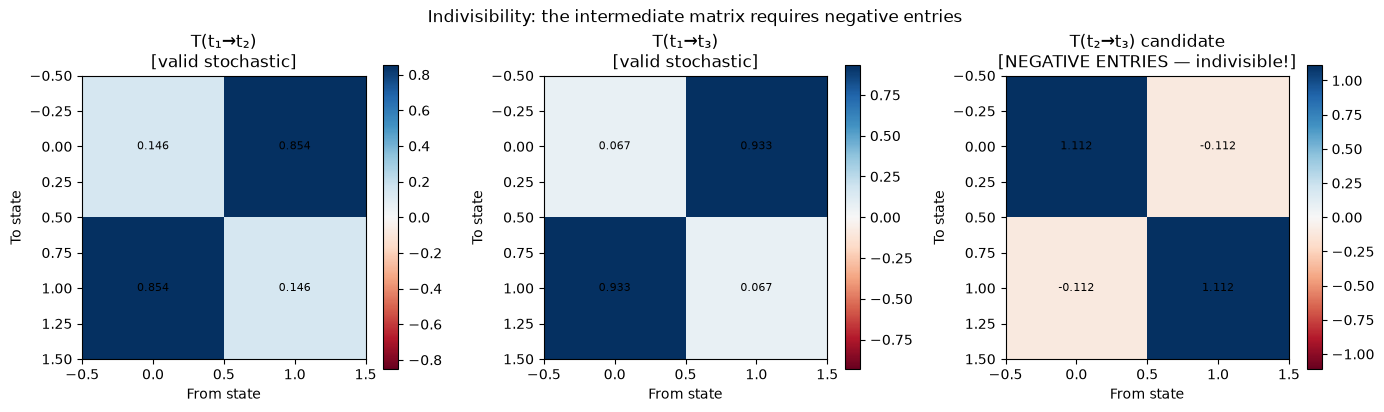

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

plot_transition_matrix(T_12, title="T(t₁→t₂)\n[valid stochastic]", ax=axes[0])
plot_transition_matrix(T_13, title="T(t₁→t₃)\n[valid stochastic]", ax=axes[1])
plot_transition_matrix(T_23_candidate,
                       title="T(t₂→t₃) candidate\n[NEGATIVE ENTRIES — indivisible!]",
                       ax=axes[2])

plt.suptitle("Indivisibility: the intermediate matrix requires negative entries")
plt.tight_layout()
plt.show()

<!-- expansion:03:recap-s1 -->
### 📝 Recap: Section 1

- A qubit evolving under $H = \tfrac{\omega}{2}\sigma_x$ defines an honest stochastic process: $T_{ij} = |U_{ij}|^2$ is non-negative and doubly stochastic at every time. Barandes calls such matrices *unistochastic*.
- The process is given by matrices from the start time. The intermediate step $T(t_2 \to t_3)$ is not given; it must be **derived**, as $T(t_1\to t_3)\,T(t_1\to t_2)^{-1}$.
- At $t_2 = 3\pi/4$, $t_3 = 5\pi/6$ the derived step is $\begin{pmatrix}1.1124&-0.1124\\-0.1124&1.1124\end{pmatrix}$. Because $T(t_1\to t_2)$ is invertible, this is the only candidate, so **no valid step exists**: the process is indivisible.
- The reason is interference. Amplitudes compose exactly; probabilities do not. For this example the cross term is $-\tfrac12\sin a\sin b = -0.0915$, and that is Paper 1's eq. 43 in miniature.
- A simple rule predicts the failure: the candidate is invalid exactly when $|\cos\omega t_3| > |\cos\omega t_2|$, i.e. when the process becomes *more* able to distinguish its starting states. The rule is not the notebook's own: it is Pimenta's two-state analysis (arXiv:2505.08785, contraction bound eq. 37, p. 14; the $\cos^2$ oscillator, eqs. 59–60, p. 17), and the two-state case of Rivas, Huelga and Plenio's Theorem 2.4 and of Buscemi and Datta (2016).


## 2. The Indivisibility Signature

The indivisibility signature turns the divisibility test into a number.
It is the magnitude of the most negative entry found across all candidate
intermediate matrices at the sampled times. Zero means no failure was found at those
times; any positive value proves the process is indivisible. The size of a positive
value mostly reflects how close the inverted matrix is to singular, so read the
signature as a detector, not as a measure of how quantum a process is.

### 🔍 Reading the code: what the signature does and does **not** measure

The signature is easy to over-read. Four caveats, all of which the ω-sweep below runs straight into.

#### 1. Zero does not mean classical — it means "divisible at the times you sampled"

The signature only inspects the time points in `process.times`. A genuinely quantum process sampled at unlucky times returns exactly $0.0$. In the sweep below, **29 of 50 ω values give a signature of precisely zero**, and not one of them is classical — every one is the same qubit under the same Hamiltonian.

A process can divide cleanly across *some* choices of times and fail across others; Paper 1's wording is that the candidate goes negative "for at least some pairs of times". What the test reports is a property of the process *and* the times you cut it at. A zero is a failure to detect, not a certificate of classicality.

#### 2. It is unbounded, so it is not a "how quantum" scale

The value is the magnitude of the most negative entry, with no normalization. Since it comes from an inverse, it blows up as $\det T(t_2,t_1) \to 0$. The sweep peaks at **16.35** — meaning an entry of $-1635\%$ — right where the determinant gets small ($|\det| \approx 0.014$). A signature of 16.35 is not "145× more quantum" than 0.112; it mostly reflects a near-singular matrix being inverted.

Treat it as a **detector** (zero vs. non-zero) rather than a **metric** (how far).

#### 3. It silently skips the singular case

In `indivisibility_signature()` (`isp/divisibility.py`):

```python
if abs(np.linalg.det(T_ij)) < tol:
    continue          # <-- skipped, contributes nothing
```

Where `check_divisibility()` stops with `failure_mode: singular_matrix`, it returns `divisible: None` (undecided), and the signature just steps over the triple. So the two functions treat the same process differently: one says it cannot decide, the other scores it 0.0, which looks like an answer. The accurate verdict for that triple is "inconclusive": the inverse-based test cannot decide it, and the inverse-free linear-program test from notebook 02 is needed.

#### 4. It is basis-dependent

$T_{ij} = |U_{ij}|^2$ is computed in the computational basis. Change basis and the numbers change — a process indivisible in one basis may look tamer in another. Nothing in the code fixes a preferred basis; it inherits whichever one the unitary was written in. Worth keeping in mind before reading a signature as an intrinsic property of the physics.

---

> **None of this undermines the notebook's conclusion.** A single non-zero signature is sufficient to prove indivisibility, and we have one: $0.112372$, from a `negative_entries` failure, at a well-conditioned triple. The caveats matter for *interpreting magnitudes and zeros*, not for the existence result.

<!-- expansion:03:deriv-signature -->
### 🧮 Worked derivation: the signature in closed form, and why the Markov chain scores exactly zero

The caveats above are easier to trust once you can compute the signature yourself.

#### The qubit: signature $= \max\!\big(0, \tfrac{|s|-1}{2}\big)$

From the 🧮 cell in Section 1, the candidate $T(t_2 \to t_3)$ has stretch

$$s = \frac{\cos(\omega t_3)}{\cos(\omega t_2)} \qquad (t_1 = 0).$$

Its entries are $(1+s)/2$ and $(1-s)/2$. If $|s| \le 1$ both are in $[0,1]$ and the signature is $0$. If $|s| > 1$, the smaller entry is $(1 - |s|)/2 < 0$. So

$$\text{signature} = \max\!\Big(0,\; \frac{|s| - 1}{2}\Big).$$

Three consequences follow, each matching a caveat above.

- **Unbounded.** As $\cos(\omega t_2) \to 0$, $|s| \to \infty$. In the sweep's peak at $\omega = 1.994$, $\cos(\omega t_2) \approx -0.0144$ (the stored output prints $|\det T(t_1\to t_2)| = 0.0144$), giving $|s| \approx 33.7$ and signature $(33.7 - 1)/2 \approx 16.35$. The "16.35" is the formula evaluated near a zero of the denominator.
- **Exactly zero, not "approximately zero".** Whenever $|\cos \omega t_3| \le |\cos \omega t_2|$, the signature is zero to machine precision. This is not a small quantum effect being rounded away. The test simply has nothing to report at those times.
- **Skipped at the singular point.** When $\cos(\omega t_2)$ is within the tolerance of zero, the code `continue`s past the triple, and the formula's denominator would be zero anyway.

#### The Markov chain: why the answer is 0.000000 for any times

A continuous-time Markov chain has $T(t \leftarrow t') = e^{L(t - t')}$. Two facts make the candidate automatically valid.

1. **It is always invertible.** $\det e^{L\,\Delta t} = e^{\operatorname{tr}(L)\,\Delta t} > 0$ (a standard matrix identity). For the generator in the next cell, $\operatorname{tr} L = -0.8$, so the determinant is positive at every time. The inverse-based test never meets a singular matrix.
2. **The candidate is the true step.** Because exponentials of the same $L$ multiply by adding exponents,

$$T(t_3 \leftarrow t_1)\,T(t_2 \leftarrow t_1)^{-1} = e^{L(t_3 - t_1)}\,e^{-L(t_2 - t_1)} = e^{L(t_3 - t_2)},$$

and $e^{L\,\Delta t}$ is a valid stochastic matrix for any generator (off-diagonals $\ge 0$, columns summing to 0) and any $\Delta t \ge 0$. That is a standard result for continuous-time Markov chains (see, for example, Norris, *Markov Chains*, §2.1 "Q-matrices and their exponentials"). So the candidate has no negative entries, and the signature is exactly zero.

**Contrast with the qubit.** A Markov chain's step depends only on the elapsed time $t_3 - t_2$. The qubit's required step is not $|U(t_3 - t_2)|^2$; it depends on how far the process had already travelled from $t_1$.


In [7]:
from isp.stochastic import make_markov_chain

L = np.array([[-0.5,  0.3], [0.5, -0.3]])
markov = make_markov_chain(2, L, times=[0.0, 3*np.pi/4, 5*np.pi/6])
quantum = make_qubit_sigmax_process(omega=1.0, times=[0.0, 3*np.pi/4, 5*np.pi/6])

sig_markov  = indivisibility_signature(markov)
sig_quantum = indivisibility_signature(quantum)

print(f"Markov chain signature:  {sig_markov:.6f}  (Markov chain: always divisible)")
print(f"Qubit sigma_x signature: {sig_quantum:.6f}  (> 0: indivisible at these times)")

Markov chain signature:  0.000000  (Markov chain: always divisible)
Qubit sigma_x signature: 0.112372  (> 0: indivisible at these times)


<!-- expansion:03:howto-cell15 -->
### 🧭 How to use this cell / what to look at

**What it computes.** It builds two processes on the same three times $[0,\; 3\pi/4,\; 5\pi/6]$ and scores each one:

- a continuous-time **Markov chain** from the generator $L = \begin{pmatrix}-0.5 & 0.3\\ 0.5 & -0.3\end{pmatrix}$. Read column by column: from state 0 the chain leaves at rate 0.5, from state 1 at rate 0.3. `make_markov_chain` in `isp/stochastic.py` stores each step as `expm(L * dt)`.
- the **qubit** from Section 1.

**What to look at.**

- `Markov chain signature: 0.000000`. This is exact, for the reason derived in the 🧮 cell above.
- `Qubit sigma_x signature: 0.112372`. This is the magnitude of the $-0.1124$ entry from Section 1.

**Background.** $L$ has eigenvalues $0$ and $-0.8$, so the chain relaxes toward $(0.375, 0.625)$ and its determinant $e^{-0.8\,t}$ shrinks but never reaches zero: it forgets steadily and never recovers, unlike Section 3's Gaussian.

**Try this.**

1. Replace the times with any increasing list, e.g. `[0.0, 0.1, 5.0, 5.01]`. Prediction: the Markov signature stays `0.000000`. The qubit's signature depends on the times you choose.
2. Try qubit times `[0.0, np.pi/4, np.pi/3]`. Prediction: qubit signature `0.000000`, the same as the Markov chain. That is exactly caveat 1 above: zero means "divisible at these times", not "classical".


non-zero (indivisibility detected) : 21 of 50
exactly zero (NOT classical -- just
  divisible at these three times)  : 29 of 50
peak signature 16.35 at omega=1.994, where |det T(t1→t2)| = 0.0144


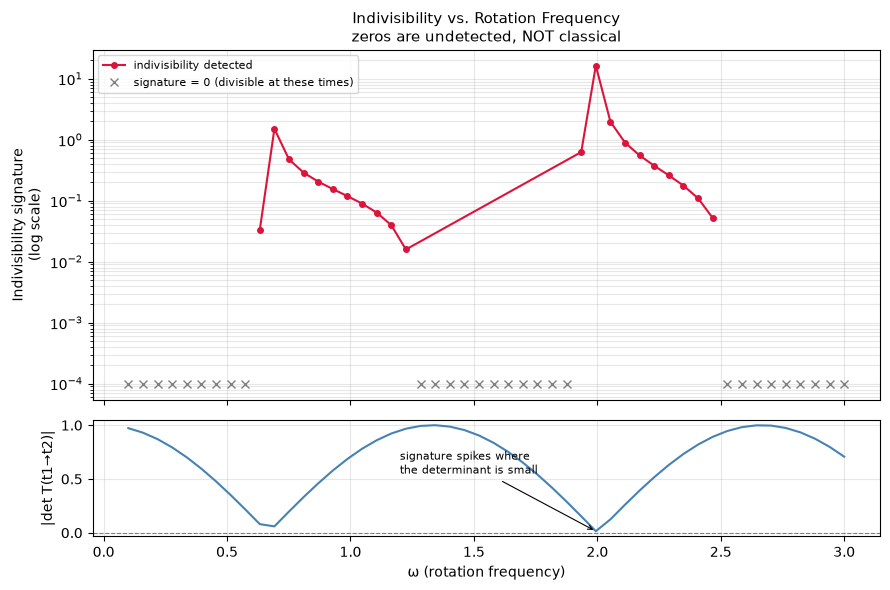


Reading this plot: the red curve shows WHERE the test fires, not 'how
quantum' the system is. The blue panel explains the tall spike -- it is an
ill-conditioned inverse, not a physically more quantum regime. And every
gray x is the same qubit, merely cut at times where it happens to divide.


In [8]:
# Log axis, because a single spike of 16.35 would flatten everything else on a linear
#    axis; zeros are marked explicitly, because a zero means "divisible at these three
#    times", not "classical".

omegas = np.linspace(0.1, 3.0, 50)
signatures, dets = [], []

for w in omegas:
    p = make_qubit_sigmax_process(omega=w, times=[0.0, 3*np.pi/4, 5*np.pi/6])
    signatures.append(indivisibility_signature(p))
    dets.append(abs(np.linalg.det(p.transition_from_to(0, 1))))

signatures = np.array(signatures)
dets = np.array(dets)
detected = signatures > 0

print(f"non-zero (indivisibility detected) : {detected.sum():>2} of {len(omegas)}")
print(f"exactly zero (NOT classical -- just")
print(f"  divisible at these three times)  : {(~detected).sum():>2} of {len(omegas)}")
print(f"peak signature {signatures.max():.2f} at omega={omegas[signatures.argmax()]:.3f}, "
      f"where |det T(t1→t2)| = {dets[signatures.argmax()]:.4f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

ax1.semilogy(omegas[detected], signatures[detected], "o-", ms=4,
             color="crimson", label="indivisibility detected")
ax1.plot(omegas[~detected], np.full((~detected).sum(), 1e-4), "x", ms=6,
         color="gray", label="signature = 0 (divisible at these times)")
ax1.set_ylabel("Indivisibility signature\n(log scale)")
ax1.set_title("Indivisibility vs. Rotation Frequency\n"
              "zeros are undetected, NOT classical", fontsize=11)
ax1.legend(fontsize=8, loc="upper left")
ax1.grid(alpha=0.3, which="both")

ax2.plot(omegas, dets, color="steelblue")
ax2.set_ylabel("|det T(t1→t2)|")
ax2.set_xlabel("ω (rotation frequency)")
ax2.axhline(0, color="gray", ls="--", lw=0.8)
ax2.grid(alpha=0.3)
ax2.annotate("signature spikes where\nthe determinant is small",
             xy=(omegas[signatures.argmax()], dets[signatures.argmax()]),
             xytext=(1.2, 0.55), fontsize=8,
             arrowprops=dict(arrowstyle="->", lw=0.8))

plt.tight_layout()
plt.show()

print("\nReading this plot: the red curve shows WHERE the test fires, not 'how")
print("quantum' the system is. The blue panel explains the tall spike -- it is an")
print("ill-conditioned inverse, not a physically more quantum regime. And every")
print("gray x is the same qubit, merely cut at times where it happens to divide.")

<!-- expansion:03:howto-sweep -->
### 🧭 How to use this figure / what to look at

**What it computes.** For 50 values of $\omega$ between 0.1 and 3.0, it builds the qubit process on the fixed times $[0, 3\pi/4, 5\pi/6]$ and records two numbers:

- the signature;
- $|\det T(t_1 \to t_2)| = |\cos(\omega \cdot 3\pi/4)|$.

**The printed numbers.**

- `non-zero (indivisibility detected): 21 of 50`;
- `exactly zero ...: 29 of 50`;
- `peak signature 16.35 at omega=1.994, where |det T(t1→t2)| = 0.0144`.

**How to read the two panels.** Top: red dots are where the test fires; gray crosses are the zeros, drawn at a nominal height $10^{-4}$ that means nothing. Bottom: $|\cos(\omega \cdot 3\pi/4)|$, which dips to zero at $\omega = 2/3$ and $\omega = 2$; the red curve shoots up near each dip.

**Predicting every dot without running the code.** From the 🧮 cells, a dot is red exactly when

$$|\cos(\omega \cdot 5\pi/6)| > |\cos(\omega \cdot 3\pi/4)|,$$

and its height is $\big(|\cos(5\pi\omega/6)| / |\cos(3\pi\omega/4)| - 1\big)/2$. Evaluating this rule at the 50 grid points reproduces the count of 21 and the peak of 16.35. The plot is a picture of two cosines racing each other.

**Try this.**

1. Replace the grid with `np.linspace(0.1, 3.0, 5000)`. Prediction: the peak near $\omega = 2$ jumps from 16.35 into the hundreds (the closed-form rule gives about 880 on that grid), because a finer grid lands closer to the zero of $\cos(3\pi\omega/4)$. The fraction of red points barely moves (about 44%, against 21/50 = 42%). This is the strongest evidence that the peak height is a sampling artifact.
2. Change the time grid to `[0, np.pi/4, np.pi/3]` inside the loop. Prediction: the pattern of red and gray changes completely, although the physics (the Hamiltonian family) is the same. Indivisibility "detected" is a property of process *and* sampling times.


### 🔭 Looking ahead: exactly how strong is the claim, and what it does not say

Everything so far establishes one direction. This is a good place to be precise about what has been shown, what the papers prove, and what lies outside these notebooks.

#### What these notebooks actually establish

| claim | status here |
|---|---|
| A unitary qubit yields a valid stochastic process whose intermediate matrix goes negative | **demonstrated** numerically, this notebook (Section 1); the example is Barandes's Paper 1, eq. 7, stated there as "provably indivisible" |
| Indivisibility does not need amplitudes: a matrix written directly as probabilities can be indivisible | **demonstrated** numerically, this notebook (Section 3); the Gaussian is also Paper 1, eq. 7 |
| Continuous-time Markov chains can never do this | **demonstrated**, notebook 02 |
| In a concrete double slit, the divisibility defect *is* the interference pattern | **demonstrated**, notebook 05 |
| Every indivisible stochastic process on a finite configuration space can be represented as a subsystem of a unistochastic (unitary-based) process | **proved in the papers** (stated in Paper 2, §4.1; proved in §5), not re-proved here |

The last row is Barandes' theorem, and no notebook in this repo re-derives it. What the lab does is exhibit the correspondence on specific finite models and check that the pieces behave as the theorem requires. That is worth something — a wrong theorem would show up as a broken example — but it is evidence, not proof, and the distinction should survive into anything written about this work.

#### The two implications, and the one that fails

Notebook 02 established one direction:

$$\textbf{Markov} \Longrightarrow \textbf{divisible}
\qquad\text{hence}\qquad
\textbf{indivisible} \Longrightarrow \textbf{non-Markovian}$$

The converse fails, and that failure is what makes indivisibility interesting: plenty of ordinary classical processes have memory and remain perfectly divisible. Indivisibility is strictly stronger than "has memory."

#### Indivisibility is not a quantum-versus-classical test

Section 3 builds an indivisible process directly from probabilities, with no Hamiltonian, amplitude, or qubit. In Barandes' framing that is expected: indivisible stochastic processes are the general case, and his theorem gives every one of them a Hilbert-space representation. So the substantive question is not whether a "classical" indivisible process exists (Section 3 has one) but whether every indivisible process really has a unistochastic dilation. Paper 2 proves that it does for finite configuration spaces; checking the proof is beyond these notebooks. The 🔭 and 📚 cells at the end of Section 3 return to this.

#### The signature is a detector

The summary describes the signature as a detector, for the reasons in the caveats cell above: it is unbounded, it largely tracks $1/|\cos\omega t|$ near the singular times, it is basis-dependent, and it returns $0.0$ both for genuinely divisible triples and for singular triples it skips. A non-zero value proves indivisibility at those times; its size is not a depth gauge.

<!-- expansion:03:papers-rivas -->
### 📚 From the papers: divisible, Markovian, and "memory" in the standard literature

The 🔭 cell above says "plenty of ordinary classical processes have memory and remain perfectly divisible" and "indivisibility is strictly stronger than 'has memory'". Those are statements from the open-systems literature. Here is where they are made precisely. The source is Rivas, Huelga and Plenio's review *Quantum non-Markovianity: characterization, quantification and detection* (in the sources as `rivas_quantum_non_markovianity.txt`).

**A non-Markovian process that is divisible (Rivas et al., §2.2, around eq. 16).** The review builds a classical process that is "non-Markovian as, for example, $P(1, t_3 \mid 0, t_2; 0, t_1) = 1$ and $P(1, t_3 \mid 0, t_2; 1, t_1) = 0$". The future depends on the state two steps back, so it has memory. Yet all its transition matrices are $\tfrac12$, so "the conditions ... are clearly fulfilled": it is divisible. This is the concrete example behind the 🔭 cell's sentence.

**At the level of one-time probabilities, divisible = Markovian (Rivas et al., Theorem 2.3 and Corollary 2.2).** Theorem 2.3: a divisible family of transition matrices "can always be seen as the transition matrices of some underlying Markov process". Corollary 2.2: "At the level of one-point probabilities, divisible and Markovian processes are equivalent. The complete hierarchy of time-conditional probabilities has to be known to make any distinctions."

This notebook uses only $T(t \leftarrow t_0)$, one-time probabilities conditioned on one earlier time. At that level, "divisible" is the strongest Markov-like statement available and "indivisible" is the only non-Markovianity you can *see*. Barandes's processes are defined by exactly these quantities (Paper 3, §2.2: the laws "contain only first-order transition probabilities").

**The contraction test (Rivas et al., §2.3, Theorem 2.4).** "Such a process is divisible if and only if the $L^1$-norm does not increase when $T(x_2, t_2 \mid x_1, t_1)$ is applied to every vector". The review also gives the operational meaning: the $L^1$ distance between two distributions measures how well one sample can tell them apart (eq. 18). For a divisible process, the chance of telling two starting distributions apart can only fall over time. For a non-divisible one, "it could be better to wait until some time ... where [the distance] increases again (without exceeding its initial value)".

**This is Section 3's two-dot picture, stated as a theorem.** The gap between the "started in 0" and "started in 1" dots is an $L^1$ distance (up to a factor of 2). Section 3's rule, "a valid step can never pull the dots apart", is the "only if" half of Theorem 2.4 for two states. Rivas et al. call it the contractive property; the notebook calls it the data-processing inequality. (For quantum channels the analogues are P- and CP-divisibility, Rivas et al. §3; these notebooks never need them.)


<!-- expansion:03:recap-s2 -->
### 📝 Recap: Section 2

- The **indivisibility signature** is the size of the most negative entry across all candidate intermediates. For the qubit it equals $\max\!\big(0, (|s|-1)/2\big)$ with $s = \cos\omega t_3 / \cos\omega t_2$.
- It is a **detector**, not a metric. Zero means "divisible at the sampled times" (29 of the 50 $\omega$ values). The 16.35 peak comes from dividing by a near-zero $\cos(\omega t_2)$.
- A continuous-time Markov chain scores **exactly** zero at any times, because $e^{L t_3} e^{-L t_2} = e^{L(t_3 - t_2)}$ is always valid and always invertible.
- In the standard literature, "divisible" and "Markovian" coincide at the level of one-time probabilities (Rivas et al., Corollary 2.2). Memory can hide inside a divisible process; indivisibility is memory that shows up even in one-time data.
- Divisibility is equivalent to "distinguishability never increases" (Rivas et al., Theorem 2.4). Section 3 is built on that idea.


## 3. A Smooth Example: The Gaussian Matrix

Indivisibility does not need a qubit. Barandes's Paper 1 (§2.1, eq. 7) and his lecture
*A New Formulation of Quantum Theory* (slide at ~17 min) give a 2×2 matrix that is smooth,
non-periodic, and "provably indivisible" (Paper 1's words). With $p(t) = e^{-t^2/\tau^2}$:

$$\Gamma(t \leftarrow 0) = \begin{pmatrix} p(t) & 1-p(t) \\ 1-p(t) & p(t) \end{pmatrix}$$

At $t=0$ it is the identity (stay put). As $t \to \infty$ it becomes a flip.
At $t^* = \tau\sqrt{\ln 2} \approx 0.833\,\tau$ it is a pure coin flip. Time is in units of $\tau$.

The process is given only as $\Gamma(t \leftarrow 0)$. Divisibility asks whether

$$\Gamma(t \leftarrow t') = \Gamma(t \leftarrow 0)\,\Gamma(t' \leftarrow 0)^{-1}$$

is a **valid** stochastic matrix: every entry $\ge 0$, every column summing to 1.
When $\Gamma(t' \leftarrow 0)$ is invertible this candidate is the *only* solution, so if it has a
negative entry, no valid $\Gamma(t \leftarrow t')$ exists.

**One number decides it.** Every matrix of the form $\begin{pmatrix} a & 1-a \\ 1-a & a\end{pmatrix}$ has a
*stretch* $s = 2a - 1$, and stretches multiply under composition. Writing
$\lambda(t) = 2p(t) - 1$ for the stretch of $\Gamma(t \leftarrow 0)$, the candidate has stretch

$$s = \frac{\lambda(t)}{\lambda(t')}, \qquad \text{and it is valid exactly when } |s| \le 1.$$

<!-- expansion:03:papers-gaussian -->
### 📚 From the lecture and Paper 1: where the Gaussian example comes from

**In the lecture (~17 min).** In *A New Formulation of Quantum Theory*, Barandes introduces divisibility as "a less well-known approximation" and states the question: "does there exist another matrix, gamma of t from t prime? ... Does a genuine stochastic matrix exist that satisfies this identity? That means it's got to be non-negative entries and its columns have to sum to one. In general, such a matrix won't exist". He then shows the Gaussian:

> "here's a very simple two by two smoothly time-dependent stochastic matrix. ... In fact, it's just a Gaussian in time. It's not periodic. Everything is perfectly smooth and differentiable. Here tau is some fixed time scale, a constant, and t is the variable."

**The Gaussian is non-Markovian and indivisible.** (The auto-generated transcript reads "It is non-marcovian and it is divisible"; from context he almost certainly said "indivisible", and Paper 1, eq. 7 calls it "provably indivisible".) It is offered as an example of the generic indivisible case, and a moment later he says "if you try to write down that intermediate gamma matrix, the intermediate stochastic matrix, it will have negative entries." Paper 1 (§2, eq. 7) states the same example in print as "provably indivisible", and this notebook's Section 3 confirms it numerically. (Lecture quotations here come from an auto-generated transcript; Paper 1 is the reference for exact wording.)

**The second example on the same slide.** "Here's another example. This one's periodic, so it exhibits [recurrences]." That periodic example is Paper 1's $f(t) = \cos^2\omega t$. In other words, it is Section 1's qubit seen as a bare stochastic matrix, with the paper's $\omega$ equal to the notebook's $\omega/2$ (Section 1 writes $\cos^2(\omega t/2)$ because it uses $H = \tfrac{\omega}{2}\sigma_x$).

**Why the Gaussian.** His stated purpose is "to make clear that this isn't some strange or unusual assumption": even a smooth, non-periodic 2×2 matrix is indivisible.

**What the notebook does with it.** The slide asserts that the intermediate "will have negative entries". The cells below find *which* pairs $(t', t)$ fail, using a one-number rule. That rule is known: it is Pimenta's two-state analysis (arXiv:2505.08785, eq. 37, p. 14, and eqs. 59–60, p. 17) and the two-state case of Buscemi and Datta (2016) and of Rivas, Huelga and Plenio's Theorem 2.4. Only the choice $\tau = 1$ and the three worked cases are the notebook's own.


### 📖 In depth: the same idea in plain words first

Before any algebra, here is the whole argument in four sentences.

1. **The data.** Run the process many times starting in state 0 and many times starting in state 1. Column $j$ of $\Gamma(t \leftarrow 0)$ is simply "where the runs that started in $j$ are found at time $t$." Nothing else is given.
2. **The question.** Could the process be broken into two legs, $0 \to t'$ and then $t' \to t$, where the second leg is an ordinary rule of the form *"if you are in state $i$ at $t'$, go to state $j$ with probability $M_{ji}$"*? That rule is $\Gamma(t \leftarrow t')$, and "valid" means it is a genuine probability table: no negative numbers, each column adds to 1.
3. **The obstacle.** Such a rule sees only the state at $t'$. It cannot tell which group a run came from. So it can make the two groups look *more alike* (blur them), but it can never make them look *less alike*.
4. **The verdict.** Whenever the two groups are easier to tell apart at $t$ than they were at $t'$, no valid rule exists. The arithmetic still produces a "rule," but it has negative entries: that is the algebra's way of saying *"you would need negative probabilities to do this."*

#### How this connects to Section 1

The qubit in Section 1 lives in exactly the same family of matrices. There, $p = \cos^2(\omega t/2)$ and the closed-form cell showed $\det T = \cos(\omega t)$. Here, write $p(t) = \cos^2\phi(t)$ with $\phi(t) = \arccos\!\big(e^{-t^2/2\tau^2}\big)$, and the same identity gives

$$\det \Gamma(t \leftarrow 0) = 2p(t) - 1 = \cos 2\phi(t) = \lambda(t).$$

The difference is the *clock*. The qubit's angle grows at a steady rate and keeps going around, so its starting state is forgotten and recovered over and over. The Gaussian's angle creeps from $0$ toward $\pi/2$ and stops. It forgets once, at $t^*$ (where $\phi = \pi/4$), and then spends the rest of time recovering. And this matrix is written down directly as probabilities. No Hamiltonian or amplitude is ever used to define it.

### 📖 In depth: deriving the stretch rule, and why the symmetric shape is not a loophole

#### Step 1: every symmetric 2×2 stochastic matrix has one free number

$$\begin{pmatrix} a & 1-a \\ 1-a & a \end{pmatrix}
= \underbrace{\tfrac12\begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}}_{\text{coin flip}}
+ \; s \cdot \underbrace{\tfrac12\begin{pmatrix} 1 & -1 \\ -1 & 1 \end{pmatrix}}_{\text{"memory" part}},
\qquad s = 2a - 1.$$

The two pieces are projectors onto the eigenvectors $(1,1)$ and $(1,-1)$. Their eigenvalues are $1$ and $s$. So $s$ measures how much of the "memory" direction survives: $s=1$ is *stay put*, $s=-1$ is *flip*, $s=0$ is *coin flip*.

#### Step 2: stretches multiply, and inverting divides

All matrices of this shape share the same eigenvectors, so multiplying two of them multiplies their eigenvalues: $s_{\text{total}} = s_1 s_2$. The inverse has stretch $1/s$. So

$$\text{candidate} = \Gamma(t \leftarrow 0)\,\Gamma(t' \leftarrow 0)^{-1}
\quad\Longrightarrow\quad s = \lambda(t) \cdot \frac{1}{\lambda(t')}.$$

#### Step 3: valid means $|s| \le 1$

The candidate's diagonal entry is $a = (1+s)/2$. It is a probability only if $0 \le a \le 1$, which is $-1 \le s \le 1$. If $s > 1$, then $a > 1$ and $1 - a < 0$. If $s < -1$, then $a < 0$. Either way a negative entry appears.

#### Step 4: "but what about non-symmetric matrices?"

The candidate came out symmetric. Could some lopsided valid matrix do the job instead? No, and here is a one-line proof that covers **every** 2×2 stochastic matrix. Let the step send state 0 to state 0 with probability $m_0$ and state 1 to state 0 with probability $m_1$. If the two groups sit at $P(0) = a$ and $1-a$ at time $t'$, then at time $t$ they sit at

$$m_0 a + m_1(1-a) \qquad\text{and}\qquad m_0(1-a) + m_1 a,$$

so the new gap is

$$\big|(m_0 - m_1)(2a - 1)\big| = |m_0 - m_1| \cdot \text{gap}(t').$$

Because $m_0, m_1 \in [0,1]$, the factor $|m_0 - m_1|$ is at most 1. **The gap can only shrink or stay the same.** This is the data-processing inequality, specialized to two states. The case-by-case linear program later double-checks it numerically.

#### Step 5: Case 3 by hand

- $p(1) = e^{-1} = 0.3679$, so $\lambda(1) = -0.2642$.
- $p(2) = e^{-4} = 0.0183$, so $\lambda(2) = -0.9634$.
- $s = -0.9634 / -0.2642 = 3.646$.
- $a = (1 + 3.646)/2 = 2.323$ and $1 - a = -1.323$.

That is the candidate printed below, computed with nothing but a calculator.

In [2]:
from matplotlib.patches import Polygon
from isp.divisibility import _intermediate_lp   # inverse-free test: does ANY valid matrix exist?

def p_of(t, tau=1.0):
    return np.exp(-(t / tau) ** 2)

def gamma(t, tau=1.0):
    p = p_of(t, tau)
    return np.array([[p, 1 - p], [1 - p, p]])

def candidate(t, t_prime):
    # The only matrix that could serve as Gamma(t <- t'), when Gamma(t' <- 0) is invertible
    return gamma(t) @ np.linalg.inv(gamma(t_prime))

T_STAR = np.sqrt(np.log(2))

def show_case(t_prime, t):
    C = candidate(t, t_prime)
    stretch = (2 * p_of(t) - 1) / (2 * p_of(t_prime) - 1)
    any_valid, _, _ = _intermediate_lp(gamma(t), gamma(t_prime), minimize_residual=False)
    print(f"Γ({t_prime}←0) =\n{gamma(t_prime).round(3)}\n")
    print(f"Γ({t}←0) =\n{gamma(t).round(3)}\n")
    print(f"Candidate Γ({t}←{t_prime}) =\n{C.round(3)}   column sums: {C.sum(axis=0).round(6)}\n")
    print(f"Stretch s = λ({t})/λ({t_prime}) = {stretch:.3f}   →  |s| {'≤' if abs(stretch) <= 1 else '>'} 1")
    print(f"Any valid stochastic matrix exists (linear-program search): {any_valid}")


def plot_reachable(ax, t_prime, t, title):
    # x = P(found in 0 | started in 0), y = P(found in 0 | started in 1): one point per time
    a = p_of(t_prime)
    target = (p_of(t), 1 - p_of(t))
    # Every valid step M maps the t' point into this parallelogram (corners: M = all-to-0,
    # identity, flip, all-to-1). Proof: (x, y) = (m0·a + m1·(1-a), m0·(1-a) + m1·a), m0, m1 in [0, 1].
    ax.add_patch(Polygon([(0, 0), (a, 1 - a), (1, 1), (1 - a, a)], closed=True,
                         color="tab:blue", alpha=0.15, label="reachable by ANY valid step from t′"))
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="diagonal: start forgotten")
    ax.plot([1, 0], [0, 1], color="gray", lw=1, label="path of Γ(t←0) for t = 0 → ∞")
    for f0, f1 in [(0.86, 0.72), (0.28, 0.14)]:
        ax.annotate("", xy=(f1, 1 - f1), xytext=(f0, 1 - f0),
                    arrowprops=dict(arrowstyle="->", color="gray"))
    ax.plot(a, 1 - a, "o", color="tab:blue", ms=9, label=f"at t′ = {t_prime}")
    ok = min(a, 1 - a) - 1e-12 <= target[0] <= max(a, 1 - a) + 1e-12
    ax.plot(*target, "o" if ok else "X", color="tab:green" if ok else "tab:red", ms=11,
            label=f"needed at t = {t}  ({'reachable' if ok else 'NOT reachable'})")
    ax.text(1.0, -0.04, "stay\n(full memory)", ha="center", va="top", fontsize=8)
    ax.text(-0.03, 0.9, "flip\n(full memory)", ha="right", va="top", fontsize=8)
    ax.text(0.57, 0.43, "coin flip", fontsize=8, va="top")
    ax.set_xlim(-0.3, 1.1); ax.set_ylim(-0.15, 1.1); ax.set_aspect("equal")
    ax.set_xlabel("P(found in 0 | started in 0)")
    ax.set_ylabel("P(found in 0 | started in 1)")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=7)


def plot_fan(ax, t_prime, t, title):
    # The candidate step as a map on the probability line: x = P(state 0) at t' → f(x) at t.
    q = candidate(t, t_prime)[0, 0]
    f = lambda x: q * x + (1 - q) * (1 - x)          # slope = 2q - 1 = stretch
    a = p_of(t_prime)
    lo, hi = min(-0.15, f(0) - 0.25, f(1) - 0.25), max(1.15, f(0) + 0.25, f(1) + 0.25)
    ax.axvspan(lo, 0, color="tab:red", alpha=0.08)
    ax.axvspan(1, hi, color="tab:red", alpha=0.08)
    for y in (0, 1):
        ax.plot([0, 1], [y, y], color="black", lw=4, solid_capstyle="butt")
    starts = [(1.0, "known: state 0", "tab:purple"), (0.0, "known: state 1", "tab:brown"),
              (a, "started in 0", "tab:blue"), (1 - a, "started in 1", "tab:orange")]
    # Stagger labels by position so neighbors never overlap
    top_order = {x: k for k, (x, *_ ) in enumerate(sorted(starts, key=lambda s: s[0]))}
    bottom_order = {x: k for k, (x, *_ ) in enumerate(sorted(starts, key=lambda s: f(s[0])))}
    for x, label, color in starts:
        fx = f(x)
        off = fx < -1e-9 or fx > 1 + 1e-9
        ax.plot([x, fx], [1, 0], color=color, lw=1.5, ls="--" if off else "-")
        ax.plot(x, 1, "o", color=color, ms=6)
        ax.plot(fx, 0, "X" if off else "o", color=color, ms=8)
        ax.annotate(label, (x, 1), textcoords="offset points",
                    xytext=(0, 8 + 11 * (top_order[x] % 2)), ha="center", fontsize=7, color=color)
        ax.annotate(f"{fx:.3f}", (fx, 0), textcoords="offset points",
                    xytext=(0, -14 - 11 * (bottom_order[x] % 2)), ha="center", fontsize=8, color=color)
    ax.text(lo + 0.02 * (hi - lo), 0.5, "not a\nprobability", color="tab:red", fontsize=8, va="center")
    ax.set_xlim(lo, hi); ax.set_ylim(-0.4, 1.3)
    ax.set_yticks([0, 1]); ax.set_yticklabels([f"t = {t}", f"t′ = {t_prime}"])
    ax.set_xlabel("P(state 0)   (thick bar = the allowed range 0…1)")
    ax.set_title(title)

### 🔍 Reading the code: what the helper cell above defines

- **`p_of`, `gamma`.** These define the process. Time is measured in units of $\tau$, so $\tau = 1$ throughout.
- **`candidate(t, t_prime)`.** This computes $\Gamma(t \leftarrow 0)\,\Gamma(t' \leftarrow 0)^{-1}$, the *only* possible $\Gamma(t \leftarrow t')$ whenever $\Gamma(t' \leftarrow 0)$ is invertible. That is every time except $t^*$.
- **`show_case`.** It prints three things:
  - the two given matrices;
  - the candidate, with its column sums (always 1, even when entries are negative; summing to 1 is not the problem);
  - the stretch and the verdict. It also runs `_intermediate_lp` from `isp/divisibility.py`, the inverse-free test from notebook 02. That test asks a linear-program solver whether **any** matrix with non-negative entries and unit column sums satisfies $M\,\Gamma(t' \leftarrow 0) = \Gamma(t \leftarrow 0)$. It does not rely on the candidate at all. It is an independent second opinion, with the same caveat noted earlier: a `False` relies on the HiGHS solver being right about infeasibility.
- **`plot_reachable`.** Each time becomes **one point** in the plane. The x-coordinate is where the "started in 0" group is ($P(0)$); the y-coordinate is where the "started in 1" group is.
  - The gray anti-diagonal is the path the process actually traces.
  - The dashed diagonal is "both groups identical," meaning the start is forgotten.
  - The blue parallelogram is every point **any** valid step could reach from the $t'$ point. Its four corners are the four extreme steps: identity, flip, "send everything to 0," and "send everything to 1." Every other valid step is a blend of these, so it lands inside.
- **`plot_fan`.** It draws the candidate step as a map from the bar at $t'$ (top) to the bar at $t$ (bottom). Each line is one starting distribution.
  - The purple and brown lines start at "certainly state 0" and "certainly state 1." They are where the candidate's columns send a known state.
  - The blue and orange lines are the two actual groups.
  - Lines that **converge** mean blurring, which a valid step can do. Lines that **spread out** mean sharpening. A spread can push the end points past 0 or 1 into the red "not a probability" zones.

<!-- expansion:03:howto-helpers -->
### 🧭 How to use the helpers: experiments you can run in a new cell

Add a scratch cell and try these. Each prediction comes from $s = \lambda(t)/\lambda(t')$ with $\lambda(t) = 2e^{-t^2} - 1$.

1. **`show_case(0.3, 0.6)`, two times before $t^*$.** $\lambda(0.3) = 0.828$ and $\lambda(0.6) = 0.395$, so $s = 0.478$. Prediction: a valid candidate with diagonal $0.739$; the LP says `True`.
2. **`show_case(0.5, 1.2)`, straddling $t^*$ but before the mirror time.** $\lambda(1.2) = -0.526$, $s = -0.944$. Prediction: valid. The candidate is "mostly flip" (diagonal $0.028$), because the groups have swapped sides. The gap ($0.526$) is still smaller than at $t' = 0.5$ ($0.558$).
3. **`show_case(0.5, 1.3)`, just past the mirror time.** $\lambda(1.3) = -0.631$, $s = -1.132$. Prediction: invalid, with a small negative diagonal ($-0.066$); the LP says `False`. Experiments 2 and 3 bracket the mirror time $t_{\text{mirror}} \approx 1.23$ derived later in the 📖 map cell.
4. **`show_case(1.5, 1.6)`, a very short leg after $t^*$.** $s = -0.845 / -0.789 = 1.071$. Prediction: invalid, diagonal $1.036$. Only slightly negative, but no valid step exists. This previews the map's conclusion that after $t^*$ *every* interval fails, however short.
5. **`show_case(2.0, 2.5)`.** $s = 1.034$. Prediction: invalid, but the most negative entry is only about $-0.017$. Far past $t^*$ the violation is small but never zero.

**Together:** whether the leg fails depends only on whether the gap *grows*, not on the direction the dots move or the length of the interval. (Avoid `candidate(t, T_STAR)`: that matrix is singular.)


### The picture behind all three cases: two dots

Run the process many times starting in state 0, and many times starting in state 1.
At each time, record $P(\text{found in } 0)$ for each group. That gives two dots on the
line from 0 to 1. **The gap between them is $|\lambda(t)|$: how much the present still
reveals about the start.**

A valid stochastic step can move the dots and can push them together (blurring), but it can
never pull them further apart. So a valid $\Gamma(t \leftarrow t')$ needs the gap at $t$ to be no
bigger than the gap at $t'$.

This gap rule is known. Rivas, Huelga and Plenio (2014, Theorem 2.4) state it for classical
processes: a process is divisible exactly when its transition matrices never increase the $L^1$ norm
of any vector. Buscemi and Datta (2016) prove the general equivalence between divisibility and
monotonic decrease of information, via the Blackwell–Sherman–Stein theorem. Pimenta (2025) gives the
complete two-state condition geometrically: there the gap is $|\det\Gamma|$, a valid step cannot
increase it, and the gap rule is the necessary part of his condition. In open-systems language, a
widening gap is information backflow (Breuer, Laine and Piilo 2009). For matrices of the symmetric form used here the rule is also sufficient (any
shrinking of the gap is done by a valid step), and the map at the end of this section confirms
it. For a general 2×2 process it is only necessary. Dots at 0.9 and 0.5 that move to 0.5 and
0.2 come closer (gap 0.4 → 0.3), yet the only candidate step has an entry −0.175: a valid step
is a straight-line map of the 0…1 bar into itself, and the line through the two required moves
runs off the bar. In a random sample of 20,000 pairs of 2×2 stochastic matrices, about 13%
blur like this and still have no valid step (columns drawn by normalizing uniform random entries;
the share depends on the sampling, and is about 17% with columns uniform on the simplex).

The plot shows the two dots over time and the three cases worked below.

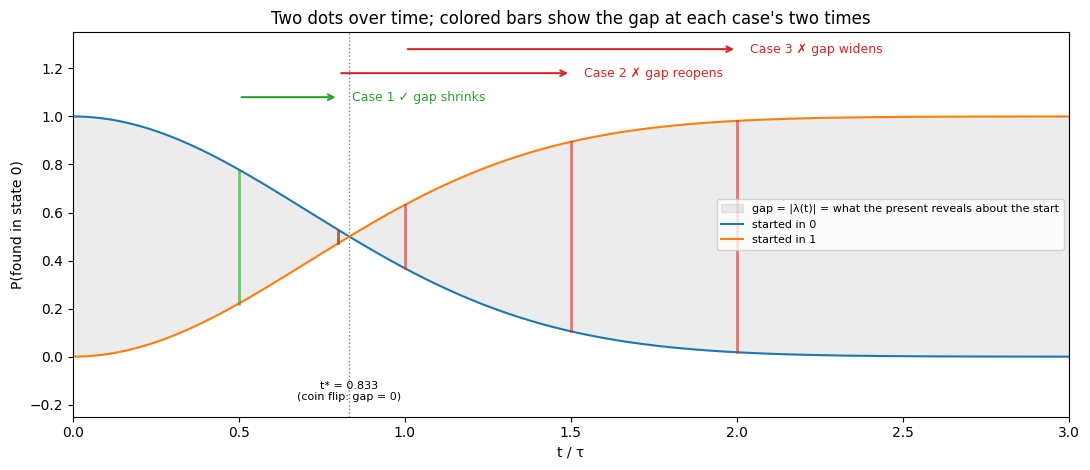

In [3]:
ts = np.linspace(0, 3, 600)
p = p_of(ts)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.fill_between(ts, p, 1 - p, color="gray", alpha=0.15, label="gap = |λ(t)| = what the present reveals about the start")
ax.plot(ts, p, color="tab:blue", label="started in 0")
ax.plot(ts, 1 - p, color="tab:orange", label="started in 1")
ax.axvline(T_STAR, color="gray", ls=":", lw=1)
ax.text(T_STAR, -0.1, f"t* = {T_STAR:.3f}\n(coin flip: gap = 0)", ha="center", va="top", fontsize=8)

cases = [(0.5, 0.8, "Case 1 ✓ gap shrinks", "tab:green"),
         (0.8, 1.5, "Case 2 ✗ gap reopens", "tab:red"),
         (1.0, 2.0, "Case 3 ✗ gap widens", "tab:red")]
for k, (tp, tt, label, color) in enumerate(cases):
    y = 1.08 + 0.1 * k
    ax.annotate("", xy=(tt, y), xytext=(tp, y), arrowprops=dict(arrowstyle="->", color=color, lw=1.5))
    ax.text(tt + 0.04, y, label, color=color, va="center", fontsize=9)
    for x in (tp, tt):
        ax.plot([x, x], [p_of(x), 1 - p_of(x)], color=color, lw=2, alpha=0.6)

ax.set_xlim(0, 3); ax.set_ylim(-0.25, 1.35)
ax.set_xlabel("t / τ"); ax.set_ylabel("P(found in state 0)")
ax.set_title("Two dots over time; colored bars show the gap at each case's two times")
ax.legend(loc="center right", fontsize=8)
plt.tight_layout()
plt.show()

### 📖 In depth: reading the two-dot plot from left to right

- **At $t = 0$.** The blue curve ("started in 0") is at 1 and the orange curve is at 0. The gap is 1: the present tells you the start perfectly.
- **From $0$ to $t^* \approx 0.833$.** The curves move toward each other. The process is *forgetting*. Any interval inside this stretch is divisible.
- **At $t^*$.** The curves cross at 0.5 and the gap is 0. For an instant, where a run is says nothing about where it began. The matrix is the coin flip $\tfrac12\begin{pmatrix}1&1\\1&1\end{pmatrix}$, which is singular, so no candidate can even be computed from here.
- **After $t^*$.** The curves keep going *in the same directions* and pull apart again. The gap reopens and heads back toward 1. The groups have swapped sides (most "started in 0" runs are now in state 1), but swapping does not matter. A flip is a perfectly valid step. What matters is the **size** of the gap, $|\lambda|$.

> **The key observation.** The gap reopens without any outside input. Something in the process's law still "knows" the starting state, even though the state at $t^*$ carries no trace of it. That knowledge is not stored in the state at $t^*$, so no rule that reads only the state at $t^*$ (or near it) can reproduce what happens next.

Case 3 sits **entirely after** $t^*$. Both of its times are on the recovering side, which is why it is the subtle one.

<!-- expansion:03:deriv-tstar-mirror -->
### 🧮 Worked derivation: $t^*$, the mirror time, and why the gap is a distance

Three small calculations that the cells above use without showing.

#### 1. The coin-flip time $t^*$

The matrix is a coin flip when $p(t) = \tfrac12$:

$$e^{-t^{*2}/\tau^2} = \tfrac12 \;\Longrightarrow\; \frac{t^{*2}}{\tau^2} = \ln 2 \;\Longrightarrow\; t^* = \tau\sqrt{\ln 2} = 0.8326\,\tau.$$

At that time $\lambda(t^*) = 2 \cdot \tfrac12 - 1 = 0$, so $\det\Gamma(t^* \leftarrow 0) = 0$ and the matrix has no inverse.

#### 2. The mirror time for a given $t' < t^*$

A leg from $t'$ to $t$ is valid while $|\lambda(t)| \le |\lambda(t')|$. Before $t^*$, $\lambda$ is positive and falling. After $t^*$, it is negative and falling toward $-1$, so $|\lambda|$ rises again. The last valid $t$ is the one where the gap has reopened to exactly its size at $t'$:

$$2p(t_{\text{mirror}}) - 1 = -\big(2p(t') - 1\big) \;\Longrightarrow\; p(t_{\text{mirror}}) = 1 - p(t').$$

So $e^{-t_{\text{mirror}}^2} = 1 - e^{-t'^2}$, which gives

$$t_{\text{mirror}} = \sqrt{-\ln\!\big(1 - e^{-t'^2}\big)}.$$

For $t' = 0.5$: $e^{-0.25} = 0.7788$, $1 - 0.7788 = 0.2212$, and $-\ln 0.2212 = 1.509$, so $t_{\text{mirror}} = 1.228$. That is the "$\approx 1.23$" quoted in the 📖 map cell. Geometrically, the mirror time is where the blue curve reaches the height the orange curve had at $t'$. The picture is symmetric about $p = \tfrac12$.

#### 3. The gap is a total-variation distance

The two groups' distributions at time $t$ are $(p, 1-p)$ and $(1-p, p)$. Their total-variation distance (half the $L^1$ distance) is

$$\tfrac12\big(|p - (1-p)| + |(1-p) - p|\big) = |2p - 1| = |\lambda(t)|.$$

So the "gap" is the standard measure of how well one observation at time $t$ can reveal which group a run came from. With equal priors, the best guessing strategy is right with probability $\tfrac12(1 + |\lambda|)$. That is the unbiased case of Rivas et al.'s eq. 18 (quoted at the end of Section 2): certainty at $t = 0$, a coin toss at $t^*$, right $98.2\%$ of the time at $t = 2$. Post-processing an observation can never make it more informative, which is why "a valid step can never pull the dots apart" is a theorem, not a heuristic.


### Case 1 — $t' = 0.5 \to t = 0.8$: valid

$$\Gamma(0.8 \leftarrow 0.5) = \begin{pmatrix} 0.549 & 0.451 \\ 0.451 & 0.549 \end{pmatrix}, \qquad s = \frac{0.055}{0.558} = 0.098$$

Both times are before $t^*$, where the process is still forgetting. The gap shrinks from 0.558
to 0.055, so a genuine blurring step does the job. On the left, the needed point sits inside
the reachable region. On the right, the step funnels the whole 0…1 bar into a narrow band:
even a system *known* to be in state 0 or 1 at $t'$ lands at 0.549 or 0.451.

Γ(0.5←0) =
[[0.779 0.221]
 [0.221 0.779]]

Γ(0.8←0) =
[[0.527 0.473]
 [0.473 0.527]]

Candidate Γ(0.8←0.5) =
[[0.549 0.451]
 [0.451 0.549]]   column sums: [1. 1.]

Stretch s = λ(0.8)/λ(0.5) = 0.098   →  |s| ≤ 1
Any valid stochastic matrix exists (linear-program search): True


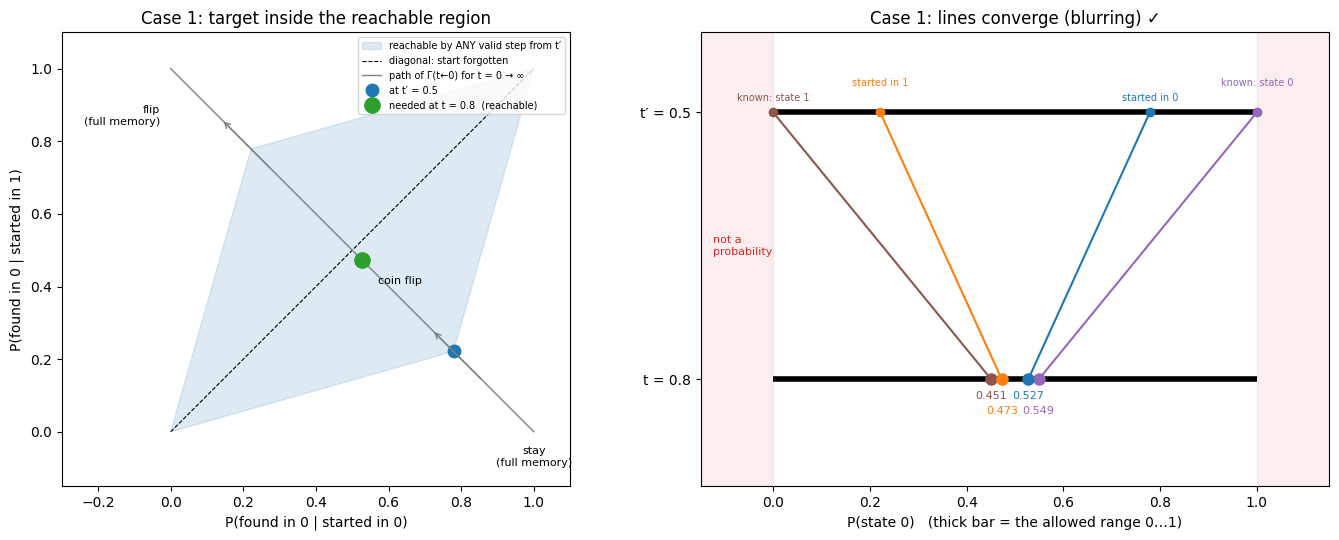

In [4]:
show_case(0.5, 0.8)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_reachable(axes[0], 0.5, 0.8, "Case 1: target inside the reachable region")
plot_fan(axes[1], 0.5, 0.8, "Case 1: lines converge (blurring) ✓")
plt.tight_layout()
plt.show()

### 📖 In depth: reading the Case 1 figures

- **Left panel.** At $t' = 0.5$ the groups are at $0.779$ and $0.221$, the blue dot. A valid step can reach anywhere in the blue diamond. The required point at $t = 0.8$ is $(0.527, 0.473)$, close to the diagonal and well inside the diamond, so the target is reachable.
- **Right panel.** The candidate sends "certainly 0" to $0.549$ and "certainly 1" to $0.451$. The whole $0\ldots1$ bar is squeezed into the band $[0.451, 0.549]$. That squeeze is the stretch $s = 0.098$: about 90% of the memory is erased on this leg.
- **The pattern to remember.** In a valid step the end points of the fan stay inside the bar.

### Case 2 — $t' = 0.8 \to t = 1.5$: dramatically invalid

$$\Gamma(1.5 \leftarrow 0.8) = \begin{pmatrix} -6.729 & 7.729 \\ 7.729 & -6.729 \end{pmatrix}, \qquad s = \frac{-0.789}{0.055} = -14.5$$

At $t' = 0.8$ the process is almost a coin flip: the two dots sit at 0.527 and 0.473, so
the present says almost nothing about the start. By $t = 1.5$ they are at 0.105 and 0.895.
The start has been *recovered*. A step that only knows the state at $t'$ cannot do that.
The arithmetic tries anyway by stretching 14.5×, which shoots the pure states to −6.7 and +7.7.

Γ(0.8←0) =
[[0.527 0.473]
 [0.473 0.527]]

Γ(1.5←0) =
[[0.105 0.895]
 [0.895 0.105]]

Candidate Γ(1.5←0.8) =
[[-6.729  7.729]
 [ 7.729 -6.729]]   column sums: [1. 1.]

Stretch s = λ(1.5)/λ(0.8) = -14.458   →  |s| > 1
Any valid stochastic matrix exists (linear-program search): False


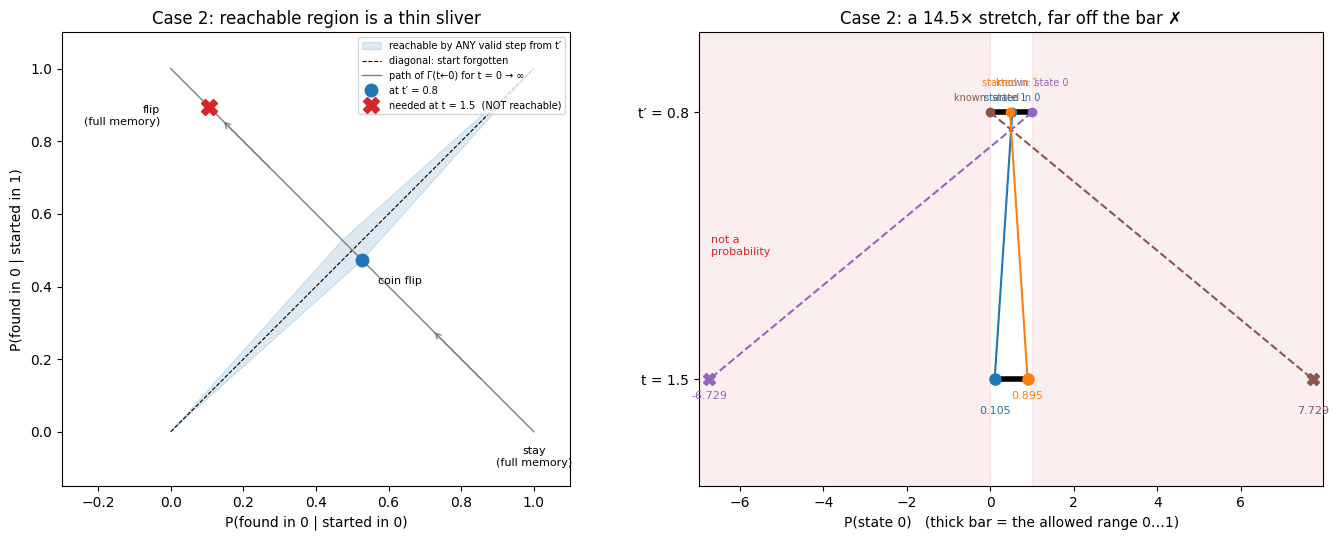

In [5]:
show_case(0.8, 1.5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_reachable(axes[0], 0.8, 1.5, "Case 2: reachable region is a thin sliver")
plot_fan(axes[1], 0.8, 1.5, "Case 2: a 14.5× stretch, far off the bar ✗")
plt.tight_layout()
plt.show()

### 📖 In depth: reading the Case 2 figures

- **Why the diamond is a sliver.** At $t' = 0.8$ the groups are at $0.527$ and $0.473$, almost on the diagonal. The diamond's corners are $(0,0)$, $(0.527, 0.473)$, $(1,1)$ and $(0.473, 0.527)$, a thin needle hugging the diagonal. In words: **from a state that has nearly forgotten its start, every valid step leads to a state that has also nearly forgotten.** You cannot get distinguishability back out of a near coin flip by any rule that only looks at the coin.
- **The target.** At $t = 1.5$ the groups need to be at $0.105$ and $0.895$, far off the needle.
- **The fan.** To turn a 0.055 gap into a 0.789 gap, the lines must spread by a factor of 14.5. The pure states then land at $-6.7$ and $+7.7$, way outside the bar.
- **Why it is so extreme.** The closer $t'$ is to $t^*$, the closer $\lambda(t')$ is to 0, and the stretch $\lambda(t)/\lambda(t')$ grows without bound. That is the same $1/\det$ blow-up the Section 1 cells described for the qubit spike.

### Case 3 — $t' = 1.0 \to t = 2.0$: invalid, and easy to miss

$$\Gamma(2.0 \leftarrow 1.0) = \begin{pmatrix} 2.323 & -1.323 \\ -1.323 & 2.323 \end{pmatrix}, \qquad s = \frac{-0.963}{-0.264} = 3.65$$

Nothing dramatic happens between $t'=1$ and $t=2$. The coin-flip moment is already in the past.
$P(\text{found in }0 \mid \text{started in } 0)$ keeps sliding the way it always has (0.368 → 0.018),
which *looks* like ordinary drift that a step-by-step process could keep going.

The catch is in the gap, not the drift. On this leg the two dots are moving **apart**
(0.264 → 0.963). The process is still recovering information it hid at $t^*$. Any valid step from
$t'=1$ can only keep the gap at 0.264 or shrink it. The best a valid step can do is keep the gap
unchanged (the identity, or a pure swap).

Read the columns of the candidate as "where a known state goes." A system *known* to be in
state 0 at $t'=1$ would have to end up with $P(\text{state } 0) = 2.323$ and $P(\text{state } 1) = -1.323$.
That is the meaning of the negative entry.

Three views below:
1. **Reachable region:** the needed point lies outside it, beyond the $t'$ point, further from the diagonal.
2. **Fan:** the lines spread out instead of converging, and the pure states land off the bar.
3. **Zoom:** both curves slide smoothly in one direction, but the gap between them is growing.

Γ(1.0←0) =
[[0.368 0.632]
 [0.632 0.368]]

Γ(2.0←0) =
[[0.018 0.982]
 [0.982 0.018]]

Candidate Γ(2.0←1.0) =
[[ 2.323 -1.323]
 [-1.323  2.323]]   column sums: [1. 1.]

Stretch s = λ(2.0)/λ(1.0) = 3.646   →  |s| > 1
Any valid stochastic matrix exists (linear-program search): False


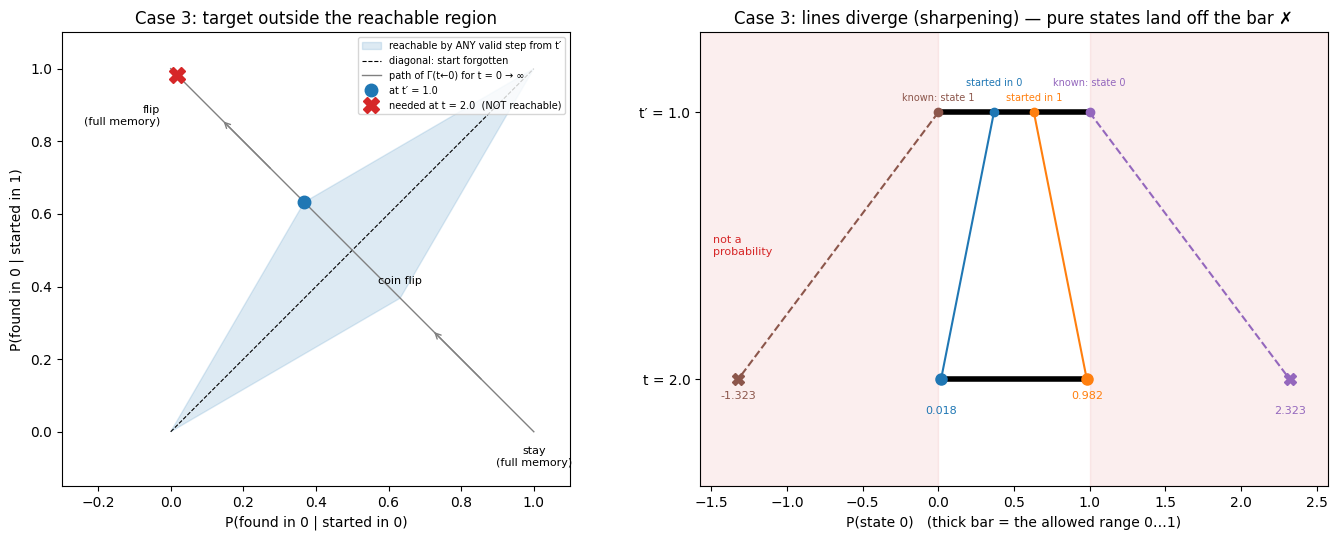

In [6]:
show_case(1.0, 2.0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_reachable(axes[0], 1.0, 2.0, "Case 3: target outside the reachable region")
plot_fan(axes[1], 1.0, 2.0, "Case 3: lines diverge (sharpening) — pure states land off the bar ✗")
plt.tight_layout()
plt.show()

<!-- expansion:03:howto-case3 -->
### 🧭 How to use the three Case cells / what to compare across them

Each Case cell prints the same five lines and draws the same two panels, so the useful thing is to read them side by side.

**The printed numbers, collected.**

- **Case 1** ($0.5 \to 0.8$): candidate diagonal $0.549$, stretch $0.098$, LP `True`.
- **Case 2** ($0.8 \to 1.5$): candidate diagonal $-6.729$, stretch $-14.458$, LP `False`.
- **Case 3** ($1.0 \to 2.0$): candidate diagonal $2.323$, stretch $3.646$, LP `False`.

**Three verdicts that always agree:** the candidate's entries, the stretch rule, and the LP. The first two agree by algebra. The LP never uses the candidate, so its agreement is a real cross-check that no lopsided valid matrix slipped past the symmetric analysis (Step 4 of the 📖 derivation proves this on paper).

**In the figures.**

- **Left panels.** Is the target marker inside the blue parallelogram? Case 1: green circle, inside. Cases 2 and 3: red X, outside.
- **Right panels.** Do the fan lines converge (blur) or spread (sharpen)? Spreading lines that cross 0 or 1 are drawn dashed and end in an X.

**Try this.**

1. `show_case(0.8, 0.82)`. Both times are just before $t^*$. $\lambda(0.8) = 0.055$ and $\lambda(0.82) = 0.021$, so $s = 0.384$. Prediction: valid (diagonal $0.692$). Close to the coin flip, a *forgetting* leg is still fine.
2. `show_case(0.85, 0.9)`. Both times are just after $t^*$. $\lambda(0.85) = -0.029$ and $\lambda(0.9) = -0.110$, so $s = 3.81$. Prediction: invalid, diagonal about $2.41$. Compare with experiment 1: one side of $t^*$ is safe, the other is not, even for legs only a few hundredths long.
3. In a new cell, run `fig, ax = plt.subplots(); plot_reachable(ax, 2.0, 1.0, "reversed")`. This asks whether the $t = 2$ matrix could be carried to the $t = 1$ matrix. Prediction: the target marker is a green circle *inside* the region. Read backwards, a recovering leg is a forgetting leg, and forgetting is always possible.


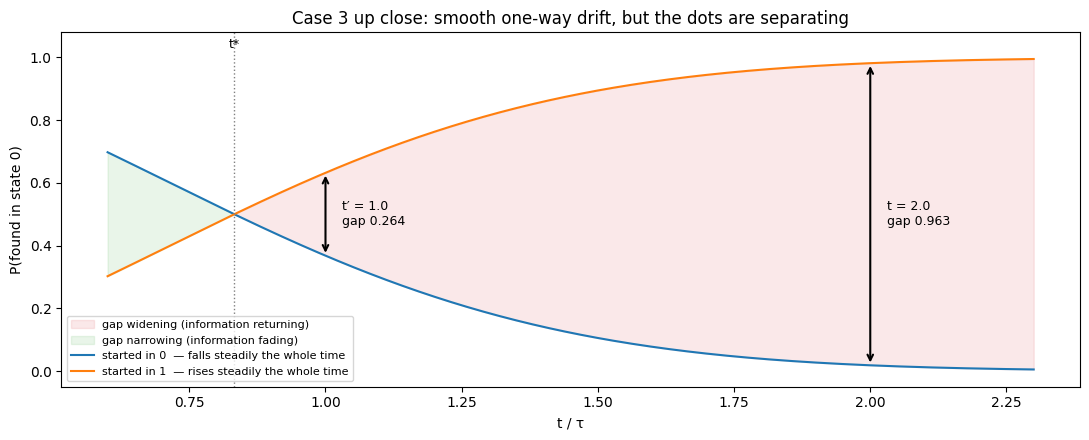

In [7]:
# Zoom: the drift looks ordinary, the gap is what gives it away
ts = np.linspace(0.6, 2.3, 400)
p = p_of(ts)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(ts, p, 1 - p, where=ts >= T_STAR, color="tab:red", alpha=0.10, label="gap widening (information returning)")
ax.fill_between(ts, p, 1 - p, where=ts <= T_STAR, color="tab:green", alpha=0.10, label="gap narrowing (information fading)")
ax.plot(ts, p, color="tab:blue", label="started in 0  — falls steadily the whole time")
ax.plot(ts, 1 - p, color="tab:orange", label="started in 1  — rises steadily the whole time")
for x, txt in [(1.0, "t′ = 1.0\ngap 0.264"), (2.0, "t = 2.0\ngap 0.963")]:
    ax.annotate("", xy=(x, 1 - p_of(x)), xytext=(x, p_of(x)),
                arrowprops=dict(arrowstyle="<->", color="black", lw=1.5))
    ax.text(x + 0.03, 0.5, txt, fontsize=9, va="center")
ax.axvline(T_STAR, color="gray", ls=":", lw=1)
ax.text(T_STAR, 1.03, "t*", ha="center", fontsize=9)
ax.set_xlabel("t / τ"); ax.set_ylabel("P(found in state 0)")
ax.set_ylim(-0.05, 1.08)
ax.set_title("Case 3 up close: smooth one-way drift, but the dots are separating")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

### 📖 In depth: Case 3, slowly

Case 3 is subtle because **every single curve looks well behaved**:

- The "started in 0" curve falls smoothly from 0.368 to 0.018.
- The "started in 1" curve rises smoothly from 0.632 to 0.982.
- Neither curve turns around, and nothing singular happens between $t' = 1$ and $t = 2$.

So it is tempting to think a step-by-step rule could just keep each curve moving the way it was going. Here is exactly why it cannot.

#### Case 3 as a word problem

A valid rule from $t'=1$ to $t=2$ is two numbers:

- $m_0$: the fraction of runs **in state 0 at $t'$** that are in state 0 at $t$;
- $m_1$: the fraction of runs **in state 1 at $t'$** that are in state 0 at $t$.

The rule cannot ask a run where it started. It only sees where the run is now. Then:

- **"Started in 0" group.** 36.8% of them are in state 0 at $t'$, and they must end up 1.8% in state 0:
  $$0.368\,m_0 + 0.632\,m_1 = 0.018$$
- **"Started in 1" group.** 63.2% are in state 0 at $t'$, and they must end up 98.2% in state 0:
  $$0.632\,m_0 + 0.368\,m_1 = 0.982$$

Subtract the first equation from the second: $0.264\,(m_0 - m_1) = 0.964$, so $m_0 - m_1 = 3.65$. Two fractions between 0 and 1 cannot differ by 3.65. Add the equations instead: $m_0 + m_1 = 1$. Together these force $m_0 = 2.323$ and $m_1 = -1.323$, which are exactly the entries of the candidate. **The negative entry is the solution to a word problem that has no real-world answer.**

#### Why both requirements cannot be met at once

The two groups are *mixed* at $t'$. Each one has runs in both states, in proportions that differ by only 26.4 points. Any rule treats a state-0 run the same no matter which group it came from. So whatever the rule does to the state-0 runs of one group, it does to the state-0 runs of the other group too. The best it can do is preserve the 26.4-point difference (identity or flip). It cannot amplify that difference into 96.4 points.

An everyday version: you have two decks of cards, each shuffled *somewhat*, one slightly more red-on-top than the other. Any shuffling procedure that looks only at the cards, not at which deck they came from, can make the decks more alike. It cannot make them *more* different. Case 3 is a process in which the decks become more different on their own.

#### A fourth view, below

The next cell plots the two equations as two lines in the $(m_0, m_1)$ plane, the space of all candidate rules. The **valid** rules form the unit square. The rule we need is where the two lines cross.

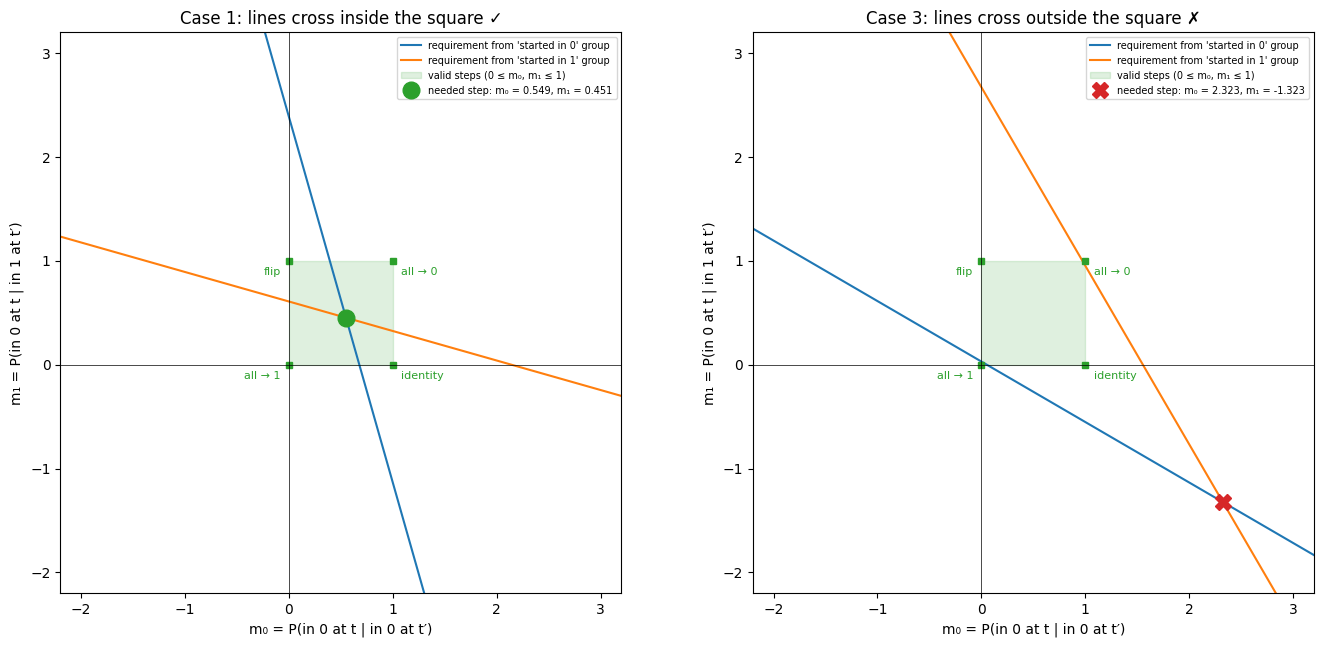

In [8]:
# 🔧 Annotated copy only. The space of ALL steps: each requirement is a line,
#    the needed step is where the lines cross, and the valid steps are the unit square.
def plot_rule_space(ax, t_prime, t, title):
    a, pt = p_of(t_prime), p_of(t)
    m = np.linspace(-2.2, 3.2, 2)
    # "started in 0":  a·m0 + (1−a)·m1 = p(t)      "started in 1":  (1−a)·m0 + a·m1 = 1 − p(t)
    ax.plot(m, (pt - a * m) / (1 - a), color="tab:blue", label="requirement from 'started in 0' group")
    ax.plot(m, ((1 - pt) - (1 - a) * m) / a, color="tab:orange", label="requirement from 'started in 1' group")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color="tab:green", alpha=0.15, label="valid steps (0 ≤ m₀, m₁ ≤ 1)"))
    for (x, y, txt, ha) in [(1, 0, "identity", "left"), (0, 1, "flip", "right"),
                            (1, 1, "all → 0", "left"), (0, 0, "all → 1", "right")]:
        ax.plot(x, y, "s", color="tab:green", ms=5)
        ax.annotate(txt, (x, y), textcoords="offset points", xytext=(6 if ha == "left" else -6, -10),
                    ha=ha, fontsize=8, color="tab:green")
    m0, m1 = np.linalg.solve([[a, 1 - a], [1 - a, a]], [pt, 1 - pt])
    ok = 0 <= m0 <= 1 and 0 <= m1 <= 1
    ax.plot(m0, m1, "o" if ok else "X", color="tab:green" if ok else "tab:red", ms=12,
            label=f"needed step: m₀ = {m0:.3f}, m₁ = {m1:.3f}")
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_xlim(-2.2, 3.2); ax.set_ylim(-2.2, 3.2); ax.set_aspect("equal")
    ax.set_xlabel("m₀ = P(in 0 at t | in 0 at t′)")
    ax.set_ylabel("m₁ = P(in 0 at t | in 1 at t′)")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=7)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
plot_rule_space(axes[0], 0.5, 0.8, "Case 1: lines cross inside the square ✓")
plot_rule_space(axes[1], 1.0, 2.0, "Case 3: lines cross outside the square ✗")
plt.tight_layout()
plt.show()

### 📖 In depth: reading the rule-space picture

- **Every point in this plane is a candidate rule** $(m_0, m_1)$. Only the green square contains genuine probability tables.
- **Each group's data rules out all but one line of rules.** The blue line lists every rule that gets the "started in 0" group right. The orange line lists every rule that gets the "started in 1" group right. The process needs both, so the answer is where the lines cross.
- **Case 1.** The lines cross at $(0.549, 0.451)$, inside the square. That is the valid step from the earlier output.
- **Case 3.** The lines cross at $(2.323, -1.323)$, outside the square. No valid rule satisfies both groups.
- **Why the lines cross far away.** The two lines have slopes $-a/(1-a)$ and $-(1-a)/a$. When the groups are nearly alike at $t'$ ($a$ near $\tfrac12$), the lines are nearly parallel, and nearly parallel lines meet far from the origin. That is Case 2's 14.5× stretch seen geometrically. At $t^*$ exactly the lines *are* parallel. They either never meet or coincide, which is the singular case where no candidate exists.

### 📖 In depth: so where *is* the missing information? A Hilbert-space view

If the state at $t'=1$ cannot account for what happens at $t=2$, the process must be "remembering" the start some other way. Barandes's answer is that **an indivisible process's law links $t$ back to $0$ directly**, and a Hilbert-space representation is a convenient way to package that.

For this matrix one such representation is easy to write down. Let $\Theta(t)$ be a rotation by the angle $\phi(t) = \arccos\sqrt{p(t)}$:

$$\Theta(t) = \begin{pmatrix} \sqrt{p} & -\sqrt{1-p} \\ \sqrt{1-p} & \sqrt{p} \end{pmatrix}, \qquad |\Theta(t)|^2 \text{ (entry by entry)} = \Gamma(t \leftarrow 0).$$

- **Amplitudes divide cleanly.** $\Theta(t \leftarrow t') = \Theta(t)\,\Theta(t')^{\mathsf T}$ is a rotation by $\phi(t) - \phi(t')$, and $\Theta(t \leftarrow t')\,\Theta(t') = \Theta(t)$ exactly. The amplitudes keep signs that the probabilities at $t'$ throw away.
- **Squaring in the middle breaks it.** $|\Theta(t \leftarrow t')|^2$ is a perfectly valid stochastic matrix. But if you square at $t'$ and *then* compose, you get $|\Theta(t \leftarrow t')|^2\,\Gamma(t' \leftarrow 0)$, which is **not** $\Gamma(t \leftarrow 0)$. The difference is the interference term, the cross-term between amplitudes that squaring at $t'$ erases.
- **Physical meaning.** In Barandes's account (Paper 1, §3.7; lecture ~42–44 min), squaring at $t'$ is what a **division event** does. When the system interacts with something that records its state at $t'$, as in a measurement, the process genuinely restarts at $t'$ and becomes divisible there. The next cell shows what Case 3 would look like in that situation.

> **A modelling note.** This $\Theta$ is one choice among many. Re-phasing its entries gives the same $\Gamma(t \leftarrow 0)$ and, by Barandes's gauge-invariance result, the same empirical predictions (Paper 1, footnote 6; Paper 3, §3.2). What happens *after* a division event is not fixed by $\Gamma(t \leftarrow 0)$ at all: it depends on how the system evolves once the interaction is over, which belongs to the description of system plus environment (Paper 1, §3.7). The dashed curve below assumes the system keeps rotating by this $\Theta$ after $t'$. Treat it as one illustrative model of a division event, not a prediction of the given process.

|Θ(t)|² equals Γ(t←0):           True
Θ(t←t′)·Θ(t′) equals Θ(t):        True
|Θ(t←t′)|² (valid stochastic) =
[[0.7566 0.2434]
 [0.2434 0.7566]]
|Θ(t←t′)|² · Γ(t′←0) =
[[0.4322 0.5678]
 [0.5678 0.4322]]
actual Γ(t←0) =
[[0.0183 0.9817]
 [0.9817 0.0183]]


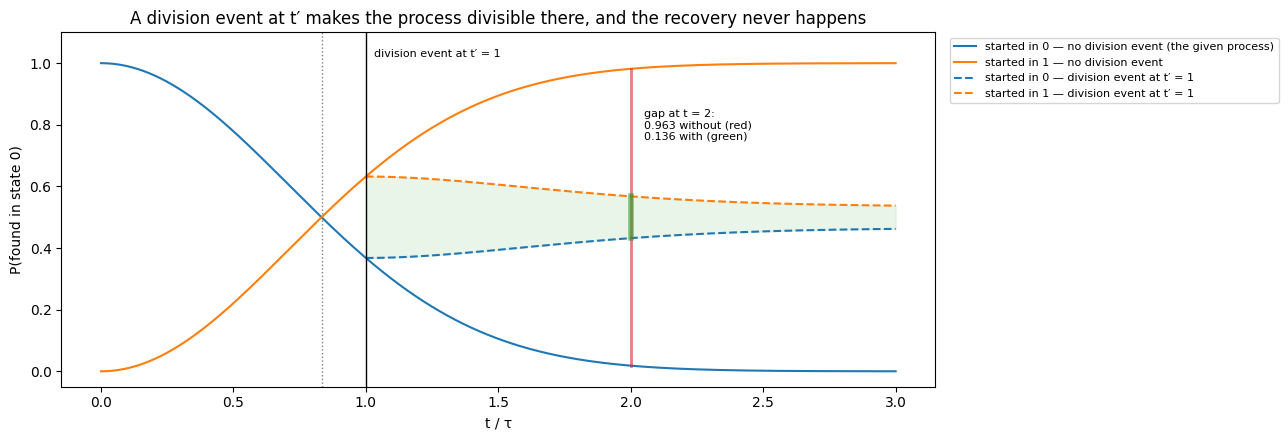

In [9]:
# 🔧 Annotated copy only. Amplitudes compose; probabilities squared at t' do not.
def theta(t):
    c, s = np.sqrt(p_of(t)), np.sqrt(1 - p_of(t))
    return np.array([[c, -s], [s, c]])

t_prime, t = 1.0, 2.0
Theta_step = theta(t) @ theta(t_prime).T
print("|Θ(t)|² equals Γ(t←0):          ", np.allclose(np.abs(theta(t)) ** 2, gamma(t)))
print("Θ(t←t′)·Θ(t′) equals Θ(t):       ", np.allclose(Theta_step @ theta(t_prime), theta(t)))
G_div = np.abs(Theta_step) ** 2
print(f"|Θ(t←t′)|² (valid stochastic) =\n{G_div.round(4)}")
print(f"|Θ(t←t′)|² · Γ(t′←0) =\n{(G_div @ gamma(t_prime)).round(4)}")
print(f"actual Γ(t←0) =\n{gamma(t).round(4)}")

# Picture: P(found in 0 | started in 0) with and without a division event at t' = 1
ts = np.linspace(0, 3, 400)
after = ts >= t_prime
with_div = [(np.abs(theta(x) @ theta(t_prime).T) ** 2 @ gamma(t_prime))[0, 0] for x in ts[after]]
with_div_1 = [(np.abs(theta(x) @ theta(t_prime).T) ** 2 @ gamma(t_prime))[0, 1] for x in ts[after]]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(ts, p_of(ts), color="tab:blue", label="started in 0 — no division event (the given process)")
ax.plot(ts, 1 - p_of(ts), color="tab:orange", label="started in 1 — no division event")
ax.plot(ts[after], with_div, color="tab:blue", ls="--", label="started in 0 — division event at t′ = 1")
ax.plot(ts[after], with_div_1, color="tab:orange", ls="--", label="started in 1 — division event at t′ = 1")
ax.fill_between(ts[after], with_div, with_div_1, color="tab:green", alpha=0.10)
ax.axvline(t_prime, color="black", lw=1)
ax.text(t_prime + 0.03, 1.02, "division event at t′ = 1", fontsize=8)
ax.axvline(T_STAR, color="gray", ls=":", lw=1)
ax.plot([2, 2], [p_of(2), 1 - p_of(2)], color="tab:red", lw=2, alpha=0.6)
ax.plot([2, 2], [with_div[np.searchsorted(ts[after], 2)], with_div_1[np.searchsorted(ts[after], 2)]],
        color="tab:green", lw=4, alpha=0.6)
ax.text(2.05, 0.75, "gap at t = 2:\n0.963 without (red)\n0.136 with (green)", fontsize=8)
ax.set_xlabel("t / τ"); ax.set_ylabel("P(found in state 0)")
ax.set_ylim(-0.05, 1.1)
ax.set_title("A division event at t′ makes the process divisible there, and the recovery never happens")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()

### 📖 In depth: reading the division-event picture

- **Solid curves.** The given process: after $t^*$ the gap reopens toward 1.
- **Dashed curves.** The same system if a division event happened at $t' = 1$, modelled as above: the system keeps rotating by $\Theta$ after the interaction. From then on, the process is the valid step $|\Theta(t \leftarrow 1)|^2$ applied to the state at $t'=1$. Since that step is valid, the gap can **never** exceed its value at $t'$ (0.264). At $t = 2$ the gap is 0.136 instead of 0.963.
- **The lesson.** Case 3's failure is not a numerical accident. The "recovered" information at $t = 2$ exists only if nothing divides the process at $t'$. Divide it, and the recovery disappears. This is the 2-state, no-slits version of the double-slit story in notebook 05, where the divisibility defect *is* the interference pattern and which-path detection erases it.

<!-- expansion:03:deriv-division-gap -->
### 🧮 Worked derivation: where $0.7566$ and the gap $0.136$ come from

The division-event cell printed $|\Theta(t \leftarrow t')|^2$ with diagonal $0.7566$, and the figure annotates the gap at $t = 2$ as $0.136$ with a division event and $0.963$ without. Both follow from the rotation angles.

**The angles.** $\Theta(t)$ rotates by $\phi(t) = \arccos\sqrt{p(t)}$.

- $\phi(1) = \arccos\sqrt{0.3679} = \arccos(0.6065) = 0.9191$ rad.
- $\phi(2) = \arccos\sqrt{0.0183} = \arccos(0.1353) = 1.4350$ rad.

**The relative rotation.** $\Theta(2 \leftarrow 1) = \Theta(2)\,\Theta(1)^{\mathsf T}$ is a rotation by $\Delta\phi = 1.4350 - 0.9191 = 0.5159$ rad. Its squared entries are $\cos^2\Delta\phi = 0.7566$ on the diagonal and $\sin^2\Delta\phi = 0.2434$ off it. These are the printed values.

**The divided process's stretch.** The stretch of $|\Theta(2 \leftarrow 1)|^2$ is $2(0.7566) - 1 = \cos(2\Delta\phi) = 0.5132$. That is less than 1, as it must be for a valid matrix.

**The gap at $t = 2$ with a division event.** Applying a valid step multiplies the gap by its stretch:

$$0.264 \times 0.5132 = 0.1356 \approx 0.136.$$

**Without the division event,** the gap is $|\lambda(2)| = 0.963$.

**The interference term, again.** The composite with a division event has diagonal $\tfrac12(1 + 0.5132 \times (-0.2642)) = 0.4322$, as printed. The true composite has diagonal $0.0183$. The difference, $0.4139$, is what squaring at $t' = 1$ throws away. It plays the same role as Section 1's $-0.0915$, but it is much larger here, because the Gaussian at these times is far into its recovery phase.


<!-- expansion:03:papers-division-events -->
### 📚 From the papers: division events and the gauge freedom

The Hilbert-space cells above lean on two ideas from the papers. Here is what the papers actually say.

#### Division events

**Definition (Paper 3, §2.2).** "Allowed conditioning times $t_0$ are called division events for the given system, and, without any real loss of generality, are assumed to include an 'initial' time 0." They "are not global properties of the whole universe, but are system-centric".

So $t = 0$ here is a division event by assumption, and every Case asks whether $t'$ is also one. After $t^*$ the map below shows it never is, unless something from outside makes it one.

**How an environment creates one (Paper 1, §3.7, eqs. 55–56).** When the subject system interacts with an environment that becomes correlated with it at $t'$, the subject's transition matrix becomes "manifestly divisible at $t'$":

$$\Gamma^S(t \leftarrow 0) = \Gamma^S(t \leftarrow t')\,\Gamma^S(t' \leftarrow 0) \qquad \text{(Paper 1, eq. 56)}$$

"It is therefore natural to refer to the new conditioning time $t'$ as a division event." The division-event cell above models exactly this: squaring at $t' = 1$, then applying the valid $|\Theta(t \leftarrow 1)|^2$.

**In the lecture (~43 min).** "This is what a division event is. It's a break in the stochastic dynamics. It's the appearance, the sudden appearance of divisibility at some time due to correlating interactions with an external system like environment." He connects it to decoherence: at $t'$ the subject's reduced density matrix is "momentarily diagonal just at t prime. And this, of course, is decoherence."

**Why everyday processes look Markovian (Paper 1, §3.7, eqs. 57–58).** If division events recur every $\delta t$ and the dynamics is homogeneous, the $n$-step matrix is $(\Gamma^S)^n$, a discrete-time Markov chain: "a theoretical explanation for the ubiquity of Markovian stochastic dynamics in so many real-world cases".

#### The gauge freedom

**Paper 1, footnote 6.** One can change "the individual entries $\Theta_{ij}(t \leftarrow 0)$ by arbitrary, time-dependent phase factors", "a previously unrecognized form of gauge invariance for all quantum systems". Such changes "alter the structure of the resulting Hilbert-space representation ahead, including the dynamics, in such a way that all empirical results remain unchanged."

Paper 3 (§3.2, eqs. 29–30) develops the same idea as the *Schur-Hadamard gauge transformation*: multiplying the entries of $\Theta(t \leftarrow 0)$ by arbitrary time-dependent phases "is a transformation of $\Theta(t \leftarrow 0)$ with no physical effects".

**What this means for the division-event picture.** A gauge choice never changes a prediction. What the given process $\Gamma(t \leftarrow 0)$ does not contain is the physics of the interaction that creates a division event. In Paper 1's model (§3.7, eqs. 44–52) that comes from the composite system of subject plus environment: after the interaction, the subject's step is $\Gamma^S(t \leftarrow t') = |U^S(t \leftarrow t')|^2$ (eq. 52), set by how the subject evolves from $t'$ onwards. The 📖 Hilbert-space cell supplies that ingredient by assumption: the subject keeps rotating by $\Theta$, so $U^S(t \leftarrow t') = \Theta(t)\,\Theta(t')^{\mathsf T}$.

Starting from a re-phased $\Theta$ and reading the post-division step off it in the same way is therefore a different assumption about the interaction, not the same model in another gauge. For example, $\Theta(t)\,\mathrm{diag}\big(1, e^{i\chi(t)}\big)$ with a time-dependent $\chi$ has the same squared entries, hence the same $\Gamma(t \leftarrow 0)$, but its step $|\Theta(2)\,\mathrm{diag}\big(1, e^{i(\chi(2) - \chi(1))}\big)\,\Theta(1)^{\mathsf T}|^2$ is a different valid matrix (diagonal $0.562$ for $\chi(t) = 0.7\,t^2$, against $0.7566$). That is why the dashed curve is one illustrative model of a division event, not a prediction of $\Gamma(t \leftarrow 0)$ alone.


### The whole picture: every pair of times

Repeating the test for every $t' < t$ gives a map of where $\Gamma(t \leftarrow t')$ fails.
The rule from the two-dot picture predicts it exactly: the candidate is invalid whenever
$|\lambda(t)| > |\lambda(t')|$. At $t' = t^*$ (white stripe) $\Gamma(t^* \leftarrow 0)$ is singular,
so no intermediate matrix exists at all, not even a signed one.

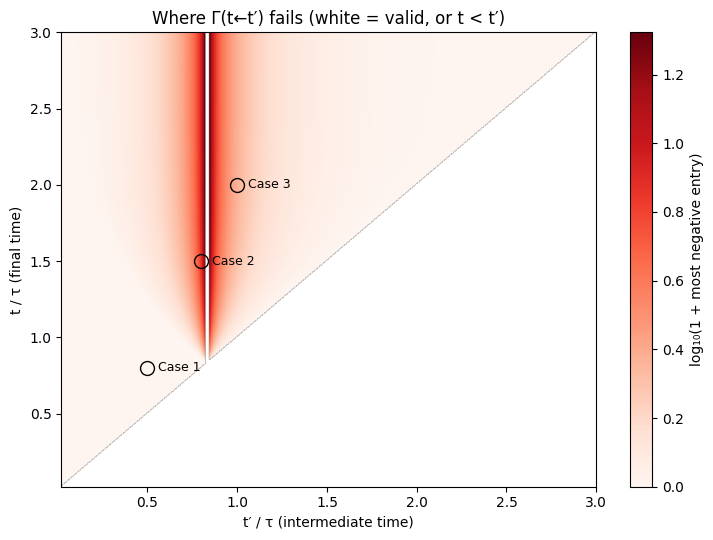

Check passed: candidate is invalid exactly when |λ(t)| > |λ(t′)|.

In [10]:
grid = np.linspace(0.02, 3, 300)
neg = np.full((len(grid), len(grid)), np.nan)
for a, tp in enumerate(grid):
    if abs(tp - T_STAR) < 1e-2:
        continue  # Γ(t'←0) singular: no candidate at all
    inv = np.linalg.inv(gamma(tp))
    for b, tt in enumerate(grid):
        if tt > tp:
            neg[b, a] = max(0.0, -(gamma(tt) @ inv).min())

fig, ax = plt.subplots(figsize=(7.5, 5.5))
im = ax.imshow(np.log10(1 + neg), origin="lower", aspect="auto", cmap="Reds",
               extent=[grid[0], grid[-1], grid[0], grid[-1]])
plt.colorbar(im, ax=ax, label="log₁₀(1 + most negative entry)")
for tp, tt, label in [(0.5, 0.8, "1"), (0.8, 1.5, "2"), (1.0, 2.0, "3")]:
    ax.plot(tp, tt, "o", mfc="none", mec="black", ms=10)
    ax.text(tp + 0.06, tt, f"Case {label}", fontsize=9, va="center")
ax.set_xlabel("t′ / τ (intermediate time)")
ax.set_ylabel("t / τ (final time)")
ax.set_title("Where Γ(t←t′) fails (white = valid, or t < t′)")
plt.tight_layout()
plt.show()

# The negativity map agrees with the gap rule everywhere it is defined
for a, tp in enumerate(grid):
    for b, tt in enumerate(grid):
        if not np.isnan(neg[b, a]):
            lam_tp, lam_t = abs(2 * p_of(tp) - 1), abs(2 * p_of(tt) - 1)
            assert (neg[b, a] > 1e-9) == (lam_t > lam_tp + 1e-9)
print("Check passed: candidate is invalid exactly when |λ(t)| > |λ(t′)|.")

<!-- expansion:03:howto-map -->
### 🧭 How to use this figure / what to look at

**What it computes.** For a 300×300 grid of pairs $(t', t)$ with $t > t'$, the most negative entry of the candidate (0 if none), coloured on a $\log_{10}(1 + \cdot)$ scale. Columns with $|t' - t^*| < 0.01$ are skipped (the white stripe). The closing **assertion** checks at every grid point that "negative entry found" is equivalent to "$|\lambda(t)| > |\lambda(t')|$"; it printed `Check passed`.

**What to look at.**

- The three circled points are Cases 1–3. Case 1 sits in white; Cases 2 and 3 sit in red.
- **Left of the stripe**, each column is white from the diagonal up to its mirror time, then red. The boundary curve is $t = \sqrt{-\ln(1 - e^{-t'^2})}$ from the 🧮 mirror-time derivation.
- **Right of the stripe**, every column is red all the way down to the diagonal.

**Why the assertion matters.** It checks the stretch rule against brute-force inversion at about 45,000 points.

**Try this.**

1. Change the colour quantity to `neg > 1e-9` (a yes/no map). Prediction: a clean two-colour picture whose boundary on the left is the mirror-time curve and whose right half is entirely "yes".
2. Replace `gamma` with the qubit's matrix, $p(t) = \cos^2(t/2)$, and move the `T_STAR` skip to $\pi/2$. Prediction: on this grid, which stops at $3 < \pi$, the picture looks qualitatively like the Gaussian's, with the stripe at $\pi/2 = 1.571$ instead of $0.833$. Extend the grid to about 7 and the pattern repeats: $|\cos t|$ rises until $\pi$, falls to zero at $3\pi/2$, then rises again. Red and white regions alternate, with a second stripe at $3\pi/2$. This is the "forgets and recovers over and over" behaviour of Section 1's 📖 cell, in picture form.


### 📖 In depth: reading the map, and a surprise it contains

- **Axes.** Each pixel is one pair $(t', t)$. Only the upper-left triangle ($t > t'$) is a real question. The lower-right triangle is left blank.
- **White pixels are valid; red pixels fail.** Deeper red means more negative entries.
- **For $t' < t^*$ (left of the stripe).** The step stays valid up to a "mirror time" where the gap has reopened to its size at $t'$, i.e. $p(t_{\text{mirror}}) = 1 - p(t')$. For $t' = 0.5$ that is $t_{\text{mirror}} = \sqrt{-\ln(1 - e^{-0.25})} \approx 1.23$. Beyond it, every $t$ fails.
- **For $t' > t^*$ (right of the stripe).** **Every** $t > t'$ fails. After $t^*$ the gap only grows, so $|\lambda(t)| > |\lambda(t')|$ for any later $t$. Once this process passes its forgetting point, **it is indivisible over every interval, however short.** Case 3 was not a cherry-picked pair; it is typical of the whole region.
- **The white stripe at $t^*$.** There $\Gamma(t^* \leftarrow 0)$ is singular and the candidate does not exist. The inverse-free linear program from notebook 02 is the right tool there, as it is for the double slit.
- **The assertion under the plot** checks that the red region is exactly the region the gap rule predicts, at every grid point.

### 🔭 Looking back: what the Gaussian shows about indivisibility

The "🔭 Looking ahead" cell in Section 2 said that indivisibility is not a quantum-versus-classical test. This section is the example behind that statement.

- **What it shows.** The Gaussian process is written down directly as probabilities, with no Hamiltonian, amplitude, or qubit. It is still indivisible. So the lab has an indivisible example that was **not** built from a unitary.
- **Why it does not undercut the correspondence.** A unitary representation exists anyway: the rotation $\Theta(t)$ above reproduces it exactly. That is what Barandes's theorem says should always happen. In his framing the right split is not "classical vs quantum" but "divisible vs indivisible," and every indivisible process, the general case, has a natural home in a Hilbert space.
- **Why 2×2 is the easy case.** Every symmetric 2×2 stochastic matrix is "unistochastic" (it equals $|U|^2$ for some unitary $U$), so finding $\Theta$ here was trivial. For more states that is no longer true in general, and the theorem in Paper 2 needs a larger Hilbert space to build the representation. The Gaussian is consistent with the theorem. It is an illustration, not a proof.

<!-- expansion:03:papers-theorem -->
### 📚 From the papers: what the stochastic-quantum theorem actually claims

The 🔭 cell above says the Gaussian "is consistent with the theorem" and that for more states "the theorem in Paper 2 needs a larger Hilbert space". Here is the theorem as stated, so you can see exactly what "consistent with" means.

**Statement (Paper 2, §4.1, display 69).**

> "Every indivisible stochastic process can be regarded as a subsystem of a unistochastic process."

Paper 2 restricts this to finite configuration spaces ("leaving the more general case to future work"). It adds: "to study the class of indivisible stochastic process, this theorem implies that it suffices to restrict one's attention to the subclass of unistochastic processes."

**What "subsystem" buys you (Paper 2, §5.7, eq. 94).** The proof may need to enlarge the space. The dilated Hilbert space has dimension $\tilde N$ with $N \le \tilde N \le N^3$. In the lecture (~31–32 min) Barandes puts it this way: "the maximum size of the [enlarged] Hilbert space you need if you started with an n-dimensional Hilbert space is n cubed". (The auto-generated transcript renders "Hilbert" here as "helper" and "neoliberal"; the quote uses "Hilbert".) For the 2×2 examples here, no enlargement is needed, because "All 2 × 2 doubly stochastic matrices are unistochastic" (Paper 2, §3.5). That is why the 🔭 cell could write down $\Theta(t)$ directly.

**What the theorem does *not* say.**

- It does not say every stochastic process is *indivisible*. Markov chains are included as a special case (Paper 2's abstract: indivisible stochastic processes "encompass many important kinds of stochastic processes, including Markov chains").
- It does not say indivisibility *requires* quantum mechanics. It says any indivisible process *can be represented* in Hilbert-space language. The Gaussian is a good illustration: it is written down without amplitudes and is still representable.
- The converse (quantum systems, with measuring devices, as indivisible processes) is attributed to other work (Paper 2, §4.2: "As shown in other work (Barandes 2025)").

**Corollary claimed (Paper 2, §4.2).** The proof "turns some of the puzzling axiomatic ingredients of quantum theory—the complex numbers, Hilbert spaces, linear-unitary time evolution, and the Born rule in particular—into the output of a theorem." Notebook 04 picks up the Born-rule part.

**How to read the lab's evidence.** In Barandes's framing, a "classical" indivisible process is not a problem: indivisible processes *are* the general case, and the theorem gives them all a Hilbert-space home. What would contradict the theorem is a finite-state indivisible process with no unistochastic dilation. The proof says there is none; checking the proof is beyond these notebooks.


<!-- expansion:03:recap-s3 -->
### 📝 Recap: Section 3

- The Gaussian matrix (Paper 1, eq. 7; lecture ~17 min) is written directly as probabilities, with no Hamiltonian, and is still indivisible.
- The candidate $\Gamma(t \leftarrow t')$ has stretch $s = \lambda(t)/\lambda(t')$ and is valid exactly when $|s| \le 1$: the gap $|\lambda|$ must not grow. The LP and the brute-force map confirm it.
- The gap is a total-variation distance: how well the present reveals the start. A valid step can only shrink it (the contractive property, Rivas et al. Theorem 2.4). The Gaussian forgets until $t^* = 0.833\,\tau$ and then recovers. Every recovering leg is indivisible, however short.
- A Hilbert-space representation exists ($\Theta(t)$, a rotation). Amplitudes divide cleanly; squaring at $t'$ (a division event) breaks the recovery. In the notebook's model of the division event (the system keeps rotating by $\Theta$ afterwards), the gap at $t = 2$ is $0.136$ instead of $0.963$.
- The Gaussian is consistent with Barandes's theorem (every indivisible process is a subsystem of a unistochastic one) but does not prove it. 2×2 is the case where no enlargement is needed.


## Summary

- A process can have valid individual transition matrices but still be indivisible
- Indivisibility shows up as negative entries in the *candidate* intermediate matrix
- This is the gap quantum processes live in: Barandes asserts that transition matrices are generically indivisible (Paper 1, §2.1, in the sentence introducing eq. 6, citing Milz & Modi (2021)); this notebook checks it on one qubit, which is his own eq. 7 example
- The qubit is not indivisible at every time: at $\omega t' = k\pi$, $\Gamma(t' \leftarrow 0)$ is the identity or the swap (a permutation), its inverse is stochastic, and the process divides there exactly (the inverse of a stochastic matrix is stochastic only for permutations: Paper 1, §3.5, eqs. 37–38)
- The indivisibility signature detects indivisibility at the sampled times: a positive value proves it, zero means nothing was found there, and its size mostly reflects how near-singular the inverted matrix is
- Indivisibility is not special to qubits: the smooth Gaussian matrix fails whenever the starting state, once nearly forgotten, becomes more distinguishable again
- A valid step can never un-blur, so un-blurring forces a negative entry. The converse needs care: for the symmetric matrices here any blurring is achieved by a valid step, but for a general 2×2 process blurring is necessary, not sufficient. The rule is known (Rivas–Huelga–Plenio (2014), Thm 2.4; Buscemi–Datta (2016); Pimenta (2025), who gives the complete two-state condition)
- 📖 Past its forgetting point $t^*$, the Gaussian process is indivisible over *every* interval; a division event at $t'$ would erase the recovery

**Next:** Notebook 04 builds the formal bridge: a qubit density matrix's diagonal is a
stochastic state, qubit evolution gives an indivisible process, and the Born rule holds
by construction in the configuration basis.

<!-- expansion:03:final-recap -->
### 📝 Notebook recap and where to go next

**The one idea.** A family of transition matrices can be perfectly valid at every time and still have no valid way to be cut at an intermediate time. When the cut is attempted with the only available candidate, negative entries appear. In both examples here, the cause is the same: between $t'$ and $t$ the process becomes *better* at distinguishing its starting states. No rule that reads only the state at $t'$ can do that.

**What you can now do.** Predict a qubit's failing times from $|\cos\omega t_3| > |\cos\omega t_2|$; compute the candidate and the signature $(|s|-1)/2$ by hand; explain the negative entry as an interference cross term (Paper 1, eq. 43); read a zero signature as "nothing detected"; and explain the Gaussian's indivisibility as lost-then-recovered information. You can also say what is demonstrated here (examples) versus proved in the papers (the theorem).

**Caveats to carry forward.**

- The indivisibility signature is a detector, not a depth gauge: a positive value proves indivisibility at the sampled times, zero means nothing was found there, and the size of a positive value mostly reflects how near-singular the inverted matrix is.
- All results are basis-dependent: $T_{ij} = |U_{ij}|^2$ is computed in the computational basis.
- `False` verdicts from the LP rely on the HiGHS solver; the repo does not verify the dual certificate.
- The division-event curve in Section 3 is one model of the interaction (the system keeps rotating by $\Theta$ after $t'$), not a prediction of $\Gamma(t \leftarrow 0)$ alone.
- Lecture quotations come from an auto-generated transcript; Paper 1 is the reference for exact wording.

**Where to go next.**

- **Notebook 04 (`04_quantum_emergence`).** It runs the correspondence the other way round: a qubit density matrix's diagonal is a stochastic state, qubit evolution gives an indivisible process, and the Born rule holds by construction in the configuration basis. The probabilities are the density matrix's diagonal, as `density_matrix_to_stochastic_state` in `isp/quantum.py` shows. The $|U_{ij}|^2$ dictionary from Section 1 and the $\Theta(t)$ construction from Section 3 are the two previews of it.
- **Notebook 05 (double slit).** The singular case met at isolated instants here ($\omega t = \pi/2$, $t = t^*$) becomes permanent, so only the inverse-free LP test works. The interference term of Section 1 becomes the interference pattern.
- **Papers:** Paper 1 §2, §3.5, §3.7; Paper 2 §4; Rivas et al. §2.2–2.3.
